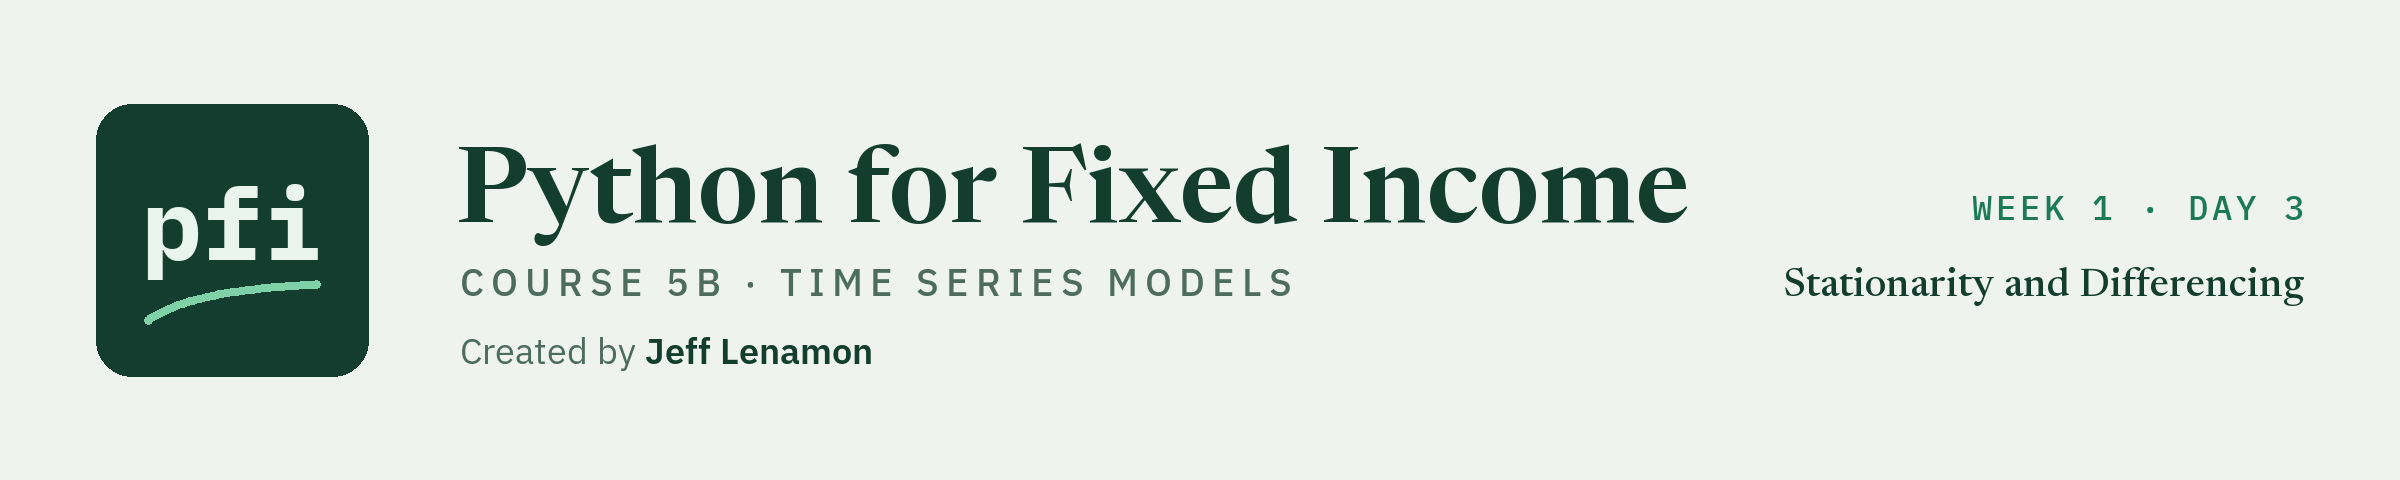

# Stationarity and Differencing

Week 1, Day 3. A model of a series needs the series to behave the same way in every year. Today you say what that means, test for it with ADF and KPSS, see why a regression of one wandering series on another lies, and difference a series until it settles.

**Data:** `treasury_par_yields.csv`, 2,940 days of U.S. Treasury par yields, 2015-01-02 to 2026-10-02: **real**, U.S. Department of the Treasury, public domain.

**Data:** `course3_synthetic_spreads.csv`, 2,940 daily investment grade and high yield spreads in bp, one per date of the Treasury file: **synthetic**, invented for Course 3, not ICE, Moody's, or any index.

> This course is educational content created in a personal capacity. Nothing here is investment advice or a recommendation to buy or sell any security. All portfolio data is synthetic.

[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/lenamonj/python-fixed-income/blob/main/course05b_time_series/week1/day3/03_stationarity_and_differencing.ipynb)

Day 2 ended on a clue: the training mean was a dozen times worse than the last value, because a yield level wanders away from the average of any earlier window. Today names that and tests for it. Every model in the next days (autoregressions, ARIMA, exponential smoothing, GARCH, lag features) assumes something about how a series behaves over time, and the assumption is called **stationarity**.

* **The task is in the past tense.** Every test today is on dates inside the development years, 2015-01-02 to 2022-12-30 (2,001 dates). The held-out years stay closed. A test result describes how a series behaved on those dates; it is not a statement about any later date.
* **Five series in bp**, as on day 2: the 2 Yr, 10 Yr, 2s10s, and the course's invented IG and HY spreads.
* **A test is not a model.** It fits nothing for scoring, so it needs no folds; it is run on the whole development span, and says so.
* **Names.** A test result is a **p-value**, a **reading**, a **verdict on the series**. Nothing today names a model output with a word about the future.

Today you will:

1. Say what stationary means, and see it in five simulated series that differ in one setting.
2. Draw a trailing mean and spread of the 10 Yr's level and of its change.
3. Run the ADF and KPSS tests (`adf_summary`, `kpss_summary`), read every setting of both, and read the two together.
4. Reproduce a spurious regression: two independent walks with a high R-squared.
5. Difference a series, see an over-differenced one, and see when a log helps.
6. Run the stationarity checklist.

Q. Set up today's work folder: the thread settings, the seed, the data files, and the modules.

## Before you start: install the libraries

Run this cell first. It checks that every library this course pins in its `requirements.txt` is installed and installs only what is missing, so it finishes in a second on a machine set up from the repo's `requirements.txt` and does the installing for you in Google Colab. If it installs anything in Colab, restart the session (Runtime, Restart session) and run the notebook again from the top.

In [1]:
# install what this notebook needs: the course's pinned libraries, only those not already present
import importlib.util
import subprocess
import sys

# import name: the pinned package, from course05b_time_series/requirements.txt
NEEDED = {
    "arch": "arch==8.0.0",
    "catboost": "catboost==1.2.10",
    "imblearn": "imbalanced-learn==0.14.2",
    "ipykernel": "ipykernel==7.4.0",
    "ipywidgets": "ipywidgets==8.1.9",
    "jinja2": "jinja2==3.1.6",
    "lightgbm": "lightgbm==4.7.0",
    "matplotlib": "matplotlib==3.11.2",
    "numpy": "numpy==2.5.3",
    "openpyxl": "openpyxl==3.1.5",
    "optuna": "optuna==5.0.0",
    "pandas": "pandas==3.0.6",
    "pytest": "pytest==9.1.1",
    "sklearn": "scikit-learn==1.9.1",
    "scipy": "scipy==1.18.1",
    "shap": "shap==0.52.0",
    "statsmodels": "statsmodels==0.15.0",
    "xgboost": "xgboost==3.4.1",
}

# a package is present when Python can find its module; the version is left as the machine has it
missing = [pin for module, pin in NEEDED.items() if importlib.util.find_spec(module) is None]
if missing:
    subprocess.run([sys.executable, "-m", "pip", "install", "--quiet", *missing], check=True)
    print(f"{len(NEEDED)} packages checked, {len(missing)} installed: restart the session and run again from the top")
else:
    print(f"{len(NEEDED)} packages checked, all present")

18 packages checked, all present


In [2]:
# today's setup: the thread settings, the modules, the seed, the course data, and a fresh work folder
import os

# one thread for the maths libraries, so every run of the notebook gives the same last digits.
# These two lines must run before numpy, pandas, statsmodels, arch, or LightGBM is imported: if you ran another
# cell first, restart the kernel and run this cell first (in Colab: Runtime, Restart session).
os.environ["OMP_NUM_THREADS"] = "1"
os.environ["OPENBLAS_NUM_THREADS"] = "1"

import importlib
import importlib.metadata
import importlib.util
import platform
import shutil
import subprocess
import sys
import tempfile
import urllib.request
from pathlib import Path

# packages a Colab runtime or a new environment may lack: stop with the line that installs the missing one
for module_name, install_name in [("statsmodels", "statsmodels"), ("arch", "arch"), ("scipy", "scipy"), ("sklearn", "scikit-learn"), ("lightgbm", "lightgbm"), ("pytest", "pytest")]:
    if importlib.util.find_spec(module_name) is None:
        raise RuntimeError(f"{install_name} is not installed. Run  !pip install {install_name}  in a new cell, "
                           "then run this cell again.")

import numpy as np
import pandas as pd

# the versions the saved outputs of this notebook came from (course05b_time_series/requirements.txt)
PINNED = {"numpy": "2.5.3", "pandas": "3.0.6", "scipy": "1.18.1", "statsmodels": "0.15.0", "arch": "8.0.0", "scikit-learn": "1.9.1", "lightgbm": "4.7.0", "matplotlib": "3.11.2", "pytest": "9.1.1"}
installed = {name: importlib.metadata.version(name) for name in PINNED}
print(f"Python {platform.python_version()}; " + ", ".join(f"{name} {version}" for name, version in installed.items()))
different = [name for name in PINNED if installed[name] != PINNED[name]]
if different:
    print(f"Not the course's pinned version: {', '.join(different)}. Printed numbers may differ in the last digits from the saved notebook.")

# the seed: one number for every random choice the course makes, so every run makes the same choices
SEED = 42

# remember the notebook's own folder, so that running this cell again starts from the same place
if "notebook_folder" not in globals():
    notebook_folder = Path.cwd()

# 1. find the course data before moving: the repo's data folder on your machine, GitHub in Colab
RAW_DATA = "https://raw.githubusercontent.com/lenamonj/python-fixed-income/main/data/"
local_data = (notebook_folder / ".." / ".." / ".." / "data").resolve()
on_github = not (local_data / "treasury_par_yields.csv").exists()

# 2. a fresh work folder for today, in the system temp folder, outside the course repo
work = Path(tempfile.mkdtemp(prefix="pfi_course5b_03_"))
os.chdir(work)

# 3. copy today's data files into the work folder
DATA_FILES = ["treasury_par_yields.csv", "course3_synthetic_spreads.csv"]
for name in DATA_FILES:
    if on_github:
        urllib.request.urlretrieve(RAW_DATA + name, work / name)
    else:
        shutil.copy(local_data / name, work / name)

# print the folder's name only: its full path would show your user name
print(f"Work folder: {work.name}, in your temp folder")
print(f"Data files from {'GitHub' if on_github else 'the data folder of the course repo'}: {', '.join(DATA_FILES)}")
print(f"SEED = {SEED}")

Python 3.13.8; numpy 2.5.3, pandas 3.0.6, scipy 1.18.1, statsmodels 0.15.0, arch 8.0.0, scikit-learn 1.9.1, lightgbm 4.7.0, matplotlib 3.11.2, pytest 9.1.1


Work folder: pfi_course5b_03_6zaz9nz_, in your temp folder
Data files from the data folder of the course repo: treasury_par_yields.csv, course3_synthetic_spreads.csv
SEED = 42


The setup cell is the same in every Course 5B notebook. `mlkit.py`, `tskit.py` and its tests below are the files as day 2 left them, and `plotkit.py` is the series' chart helpers, unchanged. Today appends two functions to `tskit.py`.

Q. Write `mlkit.py`, Course 4's complete module, unchanged. `tskit` imports it.

In [3]:
%%writefile mlkit.py
"""mlkit: the small pieces of machine learning that scikit-learn leaves to the analyst, written down and tested.

Written day by day in Python for Fixed Income, Course 4: Machine Learning.

Conventions, the same in every function:
- The seed is 42 wherever a function takes one, so every run gives the same numbers.
- Spreads are in basis points (bp). A model of log_oas is fitted in natural logs of bp; its errors are reported
  in bp after exp, and exp of a fitted log is a median-type value, not a mean.
- The positive class is 1 (default, bankrupt). Precision, recall, and F1 are for class 1 only.
- A row is flagged when its model probability is at least the threshold (probability >= threshold).
- Rows that fit a model, rows that choose a setting, and rows that report a result are kept apart; the split
  functions here prove it with a check that stops.
- Inputs of the wrong shape, or empty inputs, raise ValueError with a message that says what was wrong.
"""
import numpy as np  # arrays and arithmetic
import pandas as pd  # tables with labels
from numpy.typing import ArrayLike  # a list, an array, or a pandas Series


def assert_disjoint(train_index: ArrayLike, test_index: ArrayLike) -> None:
    """Stop if any row label is in both the training rows and the test rows.

    Inputs: the labels (or positions) of the rows in each part, for example X_train.index and X_test.index.
    Output: None when the parts share no label.
    Convention: a row in both parts is a test row the model has already seen, which flatters every metric.
    Raises AssertionError naming how many labels are in both parts, and ValueError if either part is empty.
    """
    # the labels of each part as sets
    train = set(np.asarray(train_index).tolist())
    test = set(np.asarray(test_index).tolist())
    if not train or not test:
        raise ValueError("train_index and test_index must both hold at least one label")
    # the labels found in both parts
    shared = train & test
    if shared:
        raise AssertionError(f"{len(shared)} row labels are in both the training and the test rows")


def _as_1d_array(values: ArrayLike, name: str) -> np.ndarray:
    """Return `values` as a 1-D float array, or raise ValueError naming the input."""
    array = np.asarray(values, dtype=float)
    if array.ndim != 1:
        raise ValueError(f"{name} must be one-dimensional, not {array.ndim}-dimensional")
    if array.size == 0:
        raise ValueError(f"{name} is empty")
    return array


def regression_metrics(y_true: ArrayLike, y_fitted: ArrayLike) -> dict[str, float]:
    """R-squared, mean absolute error, and root mean squared error of fitted values.

    Inputs: y_true and y_fitted, the same length, in the target's unit (for example oas in bp).
    Output: {"r2", "mae", "rmse"}. r2 is unitless, 1 - SS_res / SS_tot on the rows given (on test rows it can
    be negative); mae and rmse are in the target's unit. For a log_oas model, pass exp of both to get bp.
    Convention: equal to scikit-learn's r2_score, mean_absolute_error, and root_mean_squared_error.
    Excel: =RSQ(...) only for a straight line on one feature; =AVERAGE(ABS(a-b)) and =SQRT(SUMXMY2(a,b)/COUNT(a)).
    Raises ValueError if the inputs are empty, not one-dimensional, or of different lengths.
    """
    # check both inputs and that they line up row for row
    actual = _as_1d_array(y_true, "y_true")
    fitted = _as_1d_array(y_fitted, "y_fitted")
    if actual.size != fitted.size:
        raise ValueError(f"y_true has {actual.size} values and y_fitted has {fitted.size}")
    # each error in the target's unit
    errors = actual - fitted
    # R-squared: the share of the spread around the mean that the fitted values account for
    ss_res = float(np.sum(errors ** 2))
    ss_tot = float(np.sum((actual - actual.mean()) ** 2))
    r2 = 1 - ss_res / ss_tot
    # the average size of an error, and the square root of the average squared error
    mae = float(np.mean(np.abs(errors)))
    rmse = float(np.sqrt(np.mean(errors ** 2)))
    return {"r2": r2, "mae": mae, "rmse": rmse}


def adjusted_r2(r2: float, n_rows: int, n_features: int) -> float:
    """Adjusted R-squared: R-squared with a charge for each feature.

    Inputs: r2 on the training rows (unitless), n_rows the number of training rows, n_features the number of
    features not counting the intercept.
    Output: 1 - (1 - r2) x (n_rows - 1) / (n_rows - n_features - 1), unitless. An in-sample measure, so it is
    computed on training rows only.
    Excel: =1-(1-R2)*(n-1)/(n-k-1)
    Raises ValueError if n_features is negative or n_rows is not above n_features + 1.
    """
    # the formula needs at least one degree of freedom left after the features and the intercept
    if n_features < 0:
        raise ValueError(f"n_features must be 0 or more, not {n_features}")
    if n_rows <= n_features + 1:
        raise ValueError(f"n_rows ({n_rows}) must be greater than n_features + 1 ({n_features + 1})")
    # scale the unexplained share by the ratio of degrees of freedom
    return 1 - (1 - r2) * (n_rows - 1) / (n_rows - n_features - 1)


def rating_dummies(ratings: pd.Series, levels: list[str], reference: str) -> pd.DataFrame:
    """One indicator column per rating level except the reference level, which the intercept stands for.

    Inputs: ratings, one text rating per bond (for example "BBB+"); levels, every allowed level in the order the
    columns should follow (the rating column of ratings.csv, known in advance, not learned from the data);
    reference, the level left out.
    Output: a DataFrame with the same index, one float column (0.0 or 1.0) per level except reference, named
    rating_<level>, in the order of levels. A coefficient on rating_BB is then the difference from a bond rated
    `reference`, other features fixed.
    Convention: floats, not booleans, so every library and an Excel formula read the same 0.0 and 1.0. The
    reference is named by the caller, never chosen by alphabetical order.
    Raises ValueError if ratings is empty, reference is not in levels, or a rating is not in levels.
    """
    # check the inputs before building anything
    if len(ratings) == 0:
        raise ValueError("ratings is empty")
    if reference not in levels:
        raise ValueError(f"reference {reference!r} is not one of the levels")
    unknown = sorted(set(ratings) - set(levels))
    if unknown:
        raise ValueError(f"ratings not in levels: {unknown}")
    # one column per level, 1.0 where the bond has that rating
    columns = {f"rating_{level}": (ratings == level).astype(float) for level in levels if level != reference}
    return pd.DataFrame(columns, index=ratings.index)


def vif_table(X: pd.DataFrame) -> pd.Series:
    """Variance inflation factor of each feature: how much its coefficient's variance grows from the overlap with
    the other features.

    Input: X, the features as numeric columns (no constant column; one is added inside).
    Output: a Series named vif, one value per column, sorted from highest to lowest. VIF_j = 1 / (1 - R2_j),
    where R2_j is the R-squared of column j regressed on a constant and every other column. 1 means no overlap;
    above 5 is called high and above 10 very high, as conventions. A column that is an exact copy (or exact
    combination) of others has R2_j = 1 and VIF infinity.
    Convention: equal to statsmodels' variance_inflation_factor on X with a constant added.
    Excel: =1/(1-INDEX(LINEST(xj, other columns, TRUE, TRUE), 3, 1))
    Raises ValueError if X has fewer than two columns or fewer rows than columns plus two.
    """
    # check there is something to regress on, and enough rows to do it
    if X.shape[1] < 2:
        raise ValueError(f"X needs at least two columns, not {X.shape[1]}")
    if X.shape[0] < X.shape[1] + 2:
        raise ValueError(f"X has {X.shape[0]} rows, too few for {X.shape[1]} columns")
    values = X.to_numpy(dtype=float)
    result = {}
    for j, name in enumerate(X.columns):
        # column j is the target; a constant and the other columns are the features
        target = values[:, j]
        others = np.column_stack([np.ones(len(values)), np.delete(values, j, axis=1)])
        # least squares fit and its R-squared
        coefficients, *_ = np.linalg.lstsq(others, target, rcond=None)
        ss_res = float(np.sum((target - others @ coefficients) ** 2))
        ss_tot = float(np.sum((target - target.mean()) ** 2))
        r2 = 1 - ss_res / ss_tot
        # an exact combination of the others leaves no residual (R-squared 1 to the last digit): the VIF is infinite
        result[name] = np.inf if r2 >= 1 else 1 / (1 - r2)
    return pd.Series(result, name="vif").sort_values(ascending=False)


from scipy import stats  # Jarque-Bera and Shapiro-Wilk
from statsmodels.stats.diagnostic import het_breuschpagan  # Breusch-Pagan
from statsmodels.tools import add_constant  # the intercept column


def residual_tests(residuals: pd.Series, exog: pd.DataFrame) -> dict[str, float]:
    """p-values of three checks on a regression's residuals: constant variance and normality (two tests).

    Inputs: residuals, actual minus fitted on the training rows, in the target's unit; exog, the features the
    model was fitted on, without a constant (one is added inside), with the same rows.
    Output: {"breusch_pagan", "jarque_bera", "shapiro_wilk"}, each a p-value between 0 and 1. A small p-value
    (below 0.05, the course's convention) means the data would be surprising if the assumption held:
    - breusch_pagan: statsmodels het_breuschpagan with its default (Koenker's form, n x R-squared of the squared
      residuals regressed on a constant and exog); the assumption is constant variance;
    - jarque_bera: scipy.stats.jarque_bera (skew and kurtosis); the assumption is normal residuals;
    - shapiro_wilk: scipy.stats.shapiro; the assumption is normal residuals.
    Excel has no function for these; Breusch-Pagan can be built from LINEST and CHISQ.DIST.RT.
    Raises ValueError if the inputs are empty or have different numbers of rows.
    """
    # check the two inputs line up
    if len(residuals) == 0 or len(exog) == 0:
        raise ValueError("residuals and exog must not be empty")
    if len(residuals) != len(exog):
        raise ValueError(f"residuals has {len(residuals)} rows and exog has {len(exog)}")
    values = np.asarray(residuals, dtype=float)
    # Breusch-Pagan: returns the LM statistic, its p-value, then an F form; the LM p-value is kept
    _, bp_pvalue, _, _ = het_breuschpagan(values, add_constant(np.asarray(exog, dtype=float), has_constant="add"))
    # the two normality tests
    jb_pvalue = stats.jarque_bera(values).pvalue
    sw_pvalue = stats.shapiro(values).pvalue
    return {"breusch_pagan": float(bp_pvalue), "jarque_bera": float(jb_pvalue), "shapiro_wilk": float(sw_pvalue)}


from sklearn.pipeline import Pipeline  # the type of a chain of steps


def named_coefficients(pipeline: Pipeline) -> pd.Series:
    """The fitted coefficients of a pipeline's last step, labelled with the feature names that step saw.

    Input: a fitted scikit-learn Pipeline whose last step has coef_ (LinearRegression, Ridge, Lasso,
    LogisticRegression) and whose step before it has get_feature_names_out (a ColumnTransformer, a scaler).
    Output: a Series of coefficients indexed by feature name, in the order the model used them. Units: per unit
    of each feature as the model saw it, so per standard deviation after StandardScaler; the intercept is not
    included. For a binary LogisticRegression the one row of coef_ is used (log-odds of class 1).
    Raises ValueError if the last step has no coef_ (a tree, for example) or the pipeline has one step only.
    """
    # the model is the last step; the names come from everything before it
    if len(pipeline.steps) < 2:
        raise ValueError("the pipeline needs a preprocessing step before the model")
    model = pipeline.steps[-1][1]
    if not hasattr(model, "coef_"):
        raise ValueError(f"the last step, {type(model).__name__}, has no coef_")
    names = pipeline[:-1].get_feature_names_out()
    # a binary classifier keeps its coefficients in one row; flatten it
    coefficients = np.ravel(model.coef_)
    if coefficients.size != len(names):
        raise ValueError(f"{coefficients.size} coefficients but {len(names)} feature names")
    return pd.Series(coefficients, index=names, name="coefficient")


def odds_ratios(coefficients: pd.Series) -> pd.Series:
    """Odds ratios from logistic regression coefficients: exp of each coefficient, the intercept left out.

    Input: coefficients in log-odds, indexed by feature name, as statsmodels' Logit params (the intercept is
    named "const") or a Series with an entry named "intercept".
    Output: a Series of exp(coefficient) per feature: the factor by which the odds of class 1 multiply for one
    more unit of that feature, other features fixed. The unit is the feature's own (per 10,000 NT dollars if the
    feature was divided by 10,000; per standard deviation if it was scaled).
    Excel: =EXP(coef)
    Raises ValueError if no coefficient is left once the intercept is removed.
    """
    # leave out the intercept: exp of it is the odds when every feature is 0, not a ratio
    slopes = coefficients.drop(labels=["const", "intercept"], errors="ignore")
    if slopes.empty:
        raise ValueError("no coefficients left after removing the intercept")
    return np.exp(slopes).rename("odds_ratio")


def logistic_probability(z: float | ArrayLike) -> float | np.ndarray:
    """The logistic curve: turns log-odds z into a probability between 0 and 1.

    Input: z, a number or an array of numbers in log-odds (intercept plus coefficients times features).
    Output: 1 / (1 + exp(-z)), a float for a number, an array for an array. z = 0 gives 0.5.
    Excel: =1/(1+EXP(-z))
    """
    # numpy's exp works on a number and on an array alike
    probability = 1 / (1 + np.exp(-np.asarray(z, dtype=float)))
    return float(probability) if probability.ndim == 0 else probability


def _check_labels(y_true: ArrayLike, y_flag: ArrayLike) -> tuple[np.ndarray, np.ndarray]:
    """Return both inputs as integer arrays of 0 and 1, or raise ValueError."""
    actual = np.asarray(y_true)
    flagged = np.asarray(y_flag)
    if actual.ndim != 1 or flagged.ndim != 1 or actual.size == 0:
        raise ValueError("y_true and y_flag must be non-empty and one-dimensional")
    if actual.size != flagged.size:
        raise ValueError(f"y_true has {actual.size} values and y_flag has {flagged.size}")
    for name, values in (("y_true", actual), ("y_flag", flagged)):
        others = sorted(set(values.tolist()) - {0, 1})
        if others:
            raise ValueError(f"{name} holds labels other than 0 and 1: {others[:5]}")
    return actual.astype(int), flagged.astype(int)


def confusion_counts(y_true: ArrayLike, y_flag: ArrayLike) -> dict[str, int]:
    """The four cells of the confusion matrix, with 1 (default) as the positive class.

    Inputs: y_true, the actual outcome per row (0 or 1); y_flag, the model's flag per row (0 or 1), for example
    (probability >= threshold).
    Output: {"tn", "fp", "fn", "tp"} as whole numbers: true negatives (0 flagged 0), false positives (0 flagged
    1), false negatives (1 flagged 0), true positives (1 flagged 1). They add up to the number of rows.
    Convention: the same counts as confusion_matrix(y_true, y_flag).ravel() in scikit-learn.
    Excel: =COUNTIFS(actual,1,flag,1) and the other three combinations.
    Raises ValueError on labels other than 0 and 1, empty inputs, or inputs of different lengths.
    """
    actual, flagged = _check_labels(y_true, y_flag)
    # count each combination of actual and flag
    return {"tn": int(np.sum((actual == 0) & (flagged == 0))), "fp": int(np.sum((actual == 0) & (flagged == 1))),
            "fn": int(np.sum((actual == 1) & (flagged == 0))), "tp": int(np.sum((actual == 1) & (flagged == 1)))}


def classification_metrics(y_true: ArrayLike, y_flag: ArrayLike) -> dict[str, float]:
    """Accuracy, precision, recall, and F1 for class 1 (default), from 0/1 flags.

    Inputs: y_true and y_flag, as confusion_counts.
    Output: {"accuracy", "precision", "recall", "f1"}, each between 0 and 1:
    accuracy (TP + TN) / n; precision TP / (TP + FP), the share of flagged rows that are defaults; recall
    TP / (TP + FN), the share of defaults that are flagged; F1 their harmonic mean, 2TP / (2TP + FP + FN).
    Convention: pos_label=1, binary averaging, zero_division=0 (a model that flags nothing has precision 0, not
    an error), as scikit-learn's functions with those arguments.
    Excel: =TP/(TP+FP), =TP/(TP+FN) with the COUNTIFS cells.
    Raises ValueError as confusion_counts.
    """
    counts = confusion_counts(y_true, y_flag)
    tn, fp, fn, tp = counts["tn"], counts["fp"], counts["fn"], counts["tp"]
    # each ratio is 0 when its denominator is 0 (zero_division=0)
    accuracy = (tp + tn) / (tn + fp + fn + tp)
    precision = tp / (tp + fp) if tp + fp else 0.0
    recall = tp / (tp + fn) if tp + fn else 0.0
    f1 = 2 * tp / (2 * tp + fp + fn) if tp + fp + fn else 0.0
    return {"accuracy": accuracy, "precision": precision, "recall": recall, "f1": f1}


def threshold_for_recall(y_true: ArrayLike, proba: ArrayLike, target_recall: float) -> float:
    """The highest threshold at which the model still catches at least `target_recall` of the defaults.

    Inputs: y_true, actual outcomes (0 or 1) on the rows used to choose (validation rows, or out-of-fold
    predictions on training rows, never test rows); proba, the model probability of class 1 per row;
    target_recall, the share of defaults the desk asks to catch, above 0 and at most 1.
    Output: one of the distinct probabilities. Flagging rows with probability >= that threshold gives recall at
    least target_recall, and the next higher distinct probability would give less. A higher threshold flags
    fewer rows, so this is the threshold with the fewest flags that meets the target.
    Convention: the course's threshold rule, stated as an illustration of the recall-against-precision choice.
    Raises ValueError if target_recall is not in (0, 1], the inputs differ in length, or there is no row of
    class 1.
    """
    # check the target and the inputs
    if not 0 < target_recall <= 1:
        raise ValueError(f"target_recall must be above 0 and at most 1, not {target_recall}")
    scores = _as_1d_array(proba, "proba")
    # y_true is checked as a set of 0/1 labels the same length as proba
    actual, _ = _check_labels(y_true, np.zeros(scores.size, dtype=int))
    positives = int(actual.sum())
    if positives == 0:
        raise ValueError("y_true has no row of class 1, so recall is undefined")
    # sort rows from the highest probability down; lowering the threshold adds rows in this order
    order = np.argsort(-scores, kind="stable")
    sorted_scores, sorted_actual = scores[order], actual[order]
    # defaults caught when every row down to this one is flagged
    caught = np.cumsum(sorted_actual)
    # a threshold equal to a probability flags every row with that probability, so look at the last row of
    # each run of equal probabilities
    last_of_run = np.append(sorted_scores[1:] != sorted_scores[:-1], True)
    recall = caught[last_of_run] / positives
    thresholds = sorted_scores[last_of_run]
    # thresholds run from high to low and recall only rises: take the first one that meets the target
    meets = np.nonzero(recall >= target_recall)[0]
    return float(thresholds[meets[0]])


from sklearn.model_selection import KFold, StratifiedKFold  # the course's cross-validation splitters


def cv_folds(kind: str = "classification") -> KFold | StratifiedKFold:
    """The course's cross-validation splitter, so the choice lives in one place.

    Input: kind, "classification" or "regression".
    Output: StratifiedKFold(5, shuffle=True, random_state=42) for classification (each fold keeps the share of
    class 1), KFold(5, shuffle=True, random_state=42) for regression. Pass it as cv= to GridSearchCV,
    cross_val_score, or cross_val_predict, on training rows only.
    Convention: never for dated rows, which use walk_forward_splits or TimeSeriesSplit (no shuffle).
    Raises ValueError for any other kind.
    """
    # five folds, shuffled once with the course's seed
    if kind == "classification":
        return StratifiedKFold(n_splits=5, shuffle=True, random_state=42)
    if kind == "regression":
        return KFold(n_splits=5, shuffle=True, random_state=42)
    raise ValueError(f'kind must be "classification" or "regression", not {kind!r}')


import re  # whole-word search

from sklearn.metrics import average_precision_score, roc_auc_score

# words that turn a description into a forecast, advice, or a lending decision; a reminder, not a proof
FORECAST_WORDS = ["will", "expect", "expects", "should", "forecast", "forecasts", "cheap", "rich", "attractive",
                  "signal", "signals", "buy", "sell", "approve", "decline", "lend", "invest"]


def compare_models(models: dict, X: pd.DataFrame, y: ArrayLike, thresholds: dict[str, float]) -> pd.DataFrame:
    """One row of metrics per fitted model, on the rows given.

    Inputs: models, {name: a fitted classifier with predict_proba}, fitted by the caller on training rows;
    X and y, the rows to report on (validation rows, or the test rows once at the end); thresholds,
    {name: threshold} for every model, chosen on rows other than these test rows.
    Output: a DataFrame indexed by model name with columns roc_auc and average_precision (from probabilities,
    no threshold), then threshold, accuracy, precision, recall, f1 for rows flagged at probability >= threshold.
    Convention: nothing is fitted here; an unfitted model raises scikit-learn's NotFittedError.
    Raises ValueError if models is empty or a model has no threshold.
    """
    # check every model has a threshold before computing anything
    if not models:
        raise ValueError("models is empty")
    missing = sorted(set(models) - set(thresholds))
    if missing:
        raise ValueError(f"no threshold for: {missing}")
    rows = {}
    for name, model in models.items():
        # the model probability of class 1 per row
        proba = model.predict_proba(X)[:, 1]
        # metrics that rank without a threshold, then metrics at the model's threshold
        row = {"roc_auc": roc_auc_score(y, proba), "average_precision": average_precision_score(y, proba),
               "threshold": thresholds[name]}
        row |= classification_metrics(y, (proba >= thresholds[name]).astype(int))
        rows[name] = row
    return pd.DataFrame.from_dict(rows, orient="index")


def assert_descriptive(text: str) -> None:
    """Stop if a written description uses a word from FORECAST_WORDS.

    Input: text, a description of what a model shows.
    Output: None if no listed word appears as a whole word, in any case.
    Convention: the list is a reminder, not a proof. A text can pass and still make a forecast in other words,
    and a listed word can be harmless in context; the check makes the writer look again.
    Raises ValueError naming every listed word found, in the order of FORECAST_WORDS.
    """
    # whole words only, ignoring case: "willing" does not match "will"
    found = [word for word in FORECAST_WORDS if re.search(rf"\b{word}\b", text, flags=re.IGNORECASE)]
    if found:
        raise ValueError(f"the text uses forecast, advice, or lending words: {found}")


def walk_forward_splits(dates: pd.DatetimeIndex, min_train: int, test_size: int,
                        gap: int = 0) -> list[tuple[np.ndarray, np.ndarray]]:
    """Expanding-window splits for dated rows: train on the past, test on the rows that follow.

    Inputs: dates, the rows' dates, unique and ascending; min_train, the rows in the first training window;
    test_size, the rows in each test window; gap, rows left out between the last training row and the first
    test row (use the number of rows a target or feature spans; 0 for a same-day target).
    Output: a list of (train_positions, test_positions), integer positions into dates. Fold k trains on
    positions 0 to min_train + k x test_size - 1 and tests the next test_size positions after `gap` rows.
    The window steps forward by test_size; a last test window shorter than test_size is dropped.
    Convention: never shuffled; every training date is before every test date.
    Raises ValueError if the dates are not unique and ascending, min_train or test_size is below 1, gap is
    negative, or there are too few rows for one fold.
    """
    # check the dates and the sizes
    index = pd.DatetimeIndex(dates)
    if not (index.is_unique and index.is_monotonic_increasing):
        raise ValueError("dates must be unique and ascending")
    if min_train < 1 or test_size < 1 or gap < 0:
        raise ValueError(f"need min_train >= 1, test_size >= 1, gap >= 0; got {min_train}, {test_size}, {gap}")
    splits = []
    train_end = min_train  # one past the last training position
    # add folds while a whole test window fits after the gap
    while train_end + gap + test_size <= len(index):
        test_start = train_end + gap
        splits.append((np.arange(0, train_end), np.arange(test_start, test_start + test_size)))
        train_end += test_size
    if not splits:
        raise ValueError(f"{len(index)} rows are too few for min_train {min_train}, gap {gap}, test_size {test_size}")
    return splits


def assert_past_only(train_dates: ArrayLike, test_dates: ArrayLike, gap: int = 0,
                     calendar: ArrayLike | None = None) -> None:
    """Stop unless every training date is earlier than every test date, with a gap where one is asked for.

    Inputs: the dates of the training rows and of the test rows; gap, the rows of `calendar` that must lie
    strictly between the last training date and the first test date; calendar, every date of the dataset
    (needed when gap is above 0).
    Output: None when the split uses only the past.
    Raises AssertionError naming the last training date and the first test date when the order or the gap is
    wrong, and ValueError if either part is empty or a gap is asked for without a calendar.
    """
    train = pd.DatetimeIndex(train_dates)
    test = pd.DatetimeIndex(test_dates)
    if len(train) == 0 or len(test) == 0:
        raise ValueError("train_dates and test_dates must both hold at least one date")
    # the latest training date must come before the earliest test date
    last_train, first_test = train.max(), test.min()
    if not last_train < first_test:
        raise AssertionError(f"a training date ({last_train.date()}) is not before the first test date "
                             f"({first_test.date()})")
    if gap > 0:
        if calendar is None:
            raise ValueError("a gap is counted in rows of the calendar, so calendar is needed")
        # rows of the calendar strictly between the two dates
        days = pd.DatetimeIndex(calendar)
        between = int(((days > last_train) & (days < first_test)).sum())
        if between < gap:
            raise AssertionError(f"only {between} rows lie between {last_train.date()} and {first_test.date()}, "
                                 f"fewer than the gap of {gap}")


from collections.abc import Iterable

from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score


def elbow_table(X: ArrayLike, k_values: Iterable[int], seed: int = 42) -> pd.DataFrame:
    """Inertia and silhouette of K-means for each number of clusters, to choose k by judgement.

    Inputs: X, the features already scaled (K-means measures distance, so units decide the clusters); k_values,
    the numbers of clusters to try, each 2 or more; seed, passed as random_state.
    Output: a DataFrame indexed by k (named k) with columns inertia (the within-cluster sum of squared distances,
    in squared scaled units; it falls as k rises) and silhouette (the mean silhouette coefficient, Euclidean,
    -1 to 1; higher means tighter, better separated clusters).
    Convention: KMeans(n_clusters=k, n_init=10, random_state=seed), n_init written out.
    Raises ValueError if k_values is empty, a k is below 2, or a k is not below the number of rows.
    """
    # check the k values before fitting
    ks = list(k_values)
    if not ks:
        raise ValueError("k_values is empty")
    n_rows = len(X)
    bad = [k for k in ks if k < 2 or k >= n_rows]
    if bad:
        raise ValueError(f"each k must be at least 2 and below the {n_rows} rows; not {bad}")
    rows = []
    for k in ks:
        # fit K-means with ten starts and the course's seed
        model = KMeans(n_clusters=k, n_init=10, random_state=seed).fit(X)
        rows.append({"k": k, "inertia": float(model.inertia_), "silhouette": float(silhouette_score(X, model.labels_))})
    return pd.DataFrame(rows).set_index("k")


def cluster_profile(frame: pd.DataFrame, labels: ArrayLike, columns: list[str]) -> pd.DataFrame:
    """Describe each cluster in the data's own units: how many rows, and the median of each column.

    Inputs: frame, the rows in their original units (oas in bp, duration in years), not the scaled features the
    clusters were fitted on; labels, the cluster of each row, in the same order; columns, the columns to profile.
    Output: a DataFrame indexed by cluster (named cluster, sorted), with count and one median column per name in
    columns, in the frame's units. A profile describes a group; it does not rank one.
    Excel: a pivot table counts and averages but has no median; =MEDIAN(IF(labels=k, column)) does.
    Raises ValueError if labels and frame differ in length, frame is empty, or a column is not in frame.
    """
    # check the inputs line up and the columns exist
    labels = np.asarray(labels)
    if len(frame) == 0:
        raise ValueError("frame is empty")
    if len(labels) != len(frame):
        raise ValueError(f"labels has {len(labels)} values and frame has {len(frame)} rows")
    missing = [c for c in columns if c not in frame.columns]
    if missing:
        raise ValueError(f"columns not in frame: {missing}")
    # group the original rows by cluster, then count and take medians
    grouped = frame[columns].groupby(pd.Series(labels, index=frame.index, name="cluster"))
    profile = grouped.median()
    profile.insert(0, "count", grouped.size())
    return profile.sort_index()


from sklearn.decomposition import PCA


def pca_loadings(pca: PCA, names: list[str]) -> pd.DataFrame:
    """The loadings of a fitted PCA, one column per component, each with a fixed sign.

    Inputs: pca, a fitted scikit-learn PCA; names, the input columns in the order the PCA saw them (for the
    curve, the tenors).
    Output: a DataFrame indexed by name with columns PC1, PC2, ...: each component's weights on the inputs
    (pca.components_ transposed, unit length). A component's sign is arbitrary, so each column is multiplied by
    -1 where needed to make its loadings sum to a positive number; a rerun or another library then gives the
    same picture. Scores that match these loadings are (X - pca.mean_) @ loadings.
    Excel: no PCA function; =MMULT(changes less their column means, loadings) gives the scores.
    Raises ValueError if names does not have one entry per input column.
    """
    # one name per input column
    components = np.asarray(pca.components_)
    if len(names) != components.shape[1]:
        raise ValueError(f"{len(names)} names for {components.shape[1]} input columns")
    loadings = pd.DataFrame(components.T, index=names,
                            columns=[f"PC{i}" for i in range(1, components.shape[0] + 1)])
    # flip each component whose loadings sum to a negative number
    signs = np.where(loadings.sum(axis=0) < 0, -1.0, 1.0)
    return loadings * signs


def explained_table(pca: PCA) -> pd.DataFrame:
    """The share of variance each component of a fitted PCA accounts for, and the running total, in percent.

    Input: pca, a fitted scikit-learn PCA.
    Output: a DataFrame indexed by PC1, PC2, ... with explained_pct (explained_variance_ratio_ x 100) and
    cumulative_pct (the running sum). With every component kept, the last cumulative_pct is 100.
    """
    # the ratios in percent, then their running sum
    explained = np.asarray(pca.explained_variance_ratio_) * 100
    index = [f"PC{i}" for i in range(1, len(explained) + 1)]
    return pd.DataFrame({"explained_pct": explained, "cumulative_pct": np.cumsum(explained)}, index=index)

Writing mlkit.py


Q. Write `tskit.py` and `test_tskit.py` as they stand at the start of today: the reference version at the end of the last notebook.

In [4]:
%%writefile tskit.py
"""tskit: the time series pieces of Course 5B, written down and tested.

Written day by day in Python for Fixed Income, Course 5B: Time Series Models.

Conventions, the same in every function:
- A series is a pandas Series, and a frame a DataFrame, indexed by date: unique and ascending.
- Yields are in percent and changes in bp, as in the Treasury file; each docstring states its unit.
- A function that describes or repairs data never fills an earlier date from a later one unless its docstring
  says so in its first lines.
- A fitted value is for a date inside the file, from a model fitted on earlier dates only; it is never a
  statement about a date after the file ends.
- Inputs of the wrong shape, or empty inputs, raise ValueError with a message that says what was wrong.
"""
import numpy as np  # arrays and arithmetic
import pandas as pd  # dated tables

import mlkit  # Course 4's module: its walk-forward splits and its past-only check are used from day 2


def _check_dated(index: pd.Index, name: str) -> None:
    """Stop unless the index is a DatetimeIndex that is not empty, unique, and ascending."""
    if not isinstance(index, pd.DatetimeIndex):
        raise ValueError(f"{name} must be indexed by date (a DatetimeIndex)")
    if len(index) == 0:
        raise ValueError(f"{name} is empty")
    if not (index.is_unique and index.is_monotonic_increasing):
        raise ValueError(f"{name} must have unique dates in ascending order")


def gap_report(frame: pd.DataFrame) -> pd.DataFrame:
    """One row per column of a dated frame: where the series starts and ends, and where its values are blank.

    Input: frame, dated rows (a DatetimeIndex, unique and ascending), one column per series.
    Output: a DataFrame indexed by column name, with
      rows: the rows in the frame;
      first_valid, last_valid: the first and last dates that hold a value (NaT for a column with none);
      before_start: blank rows before first_valid (a series that had not started yet);
      blank_inside: blank cells from first_valid to last_valid (outages and gaps inside the series);
      after_end: blank rows after last_valid;
      longest_inside: the longest run of consecutive blank rows inside the series (0 when there is none).
    A date with no row at all (a market holiday) is not in the frame, so it is not counted here: compare the
    index with a calendar to find those.
    Raises ValueError for an empty frame or an index that is not dated, unique, and ascending.
    """
    _check_dated(frame.index, "frame")
    rows = []
    for column in frame.columns:
        blank = frame[column].isna().to_numpy()
        first, last = frame[column].first_valid_index(), frame[column].last_valid_index()
        if first is None:
            # no value at all: every row counts as before the start
            rows.append({"column": column, "rows": len(blank), "first_valid": pd.NaT, "last_valid": pd.NaT,
                         "before_start": len(blank), "blank_inside": 0, "after_end": 0, "longest_inside": 0})
            continue
        start, end = frame.index.get_loc(first), frame.index.get_loc(last)
        inside = blank[start:end + 1]
        runs = gap_runs(frame[column].iloc[start:end + 1]) if inside.any() else None
        rows.append({"column": column, "rows": len(blank), "first_valid": first, "last_valid": last,
                     "before_start": start, "blank_inside": int(inside.sum()), "after_end": len(blank) - 1 - end,
                     "longest_inside": int(runs["rows"].max()) if runs is not None else 0})
    return pd.DataFrame(rows).set_index("column")


def gap_runs(series: pd.Series) -> pd.DataFrame:
    """Every run of consecutive blank values in a dated series: its first and last dates and its length in rows.

    Input: series, values indexed by date (unique and ascending).
    Output: a DataFrame with one row per run, in date order, and columns
      start, end: the first and last dates of the run;
      rows: the number of blank rows in the run;
      kind: "before start" for a run on the first row (the series had not started), "after end" for a run that
      reaches the last row, and "inside" for every other run.
    With nothing blank, an empty DataFrame with the same columns. A run counts rows, not calendar days: a blank
    Friday and the blank Monday after it are one run of 2 rows.
    Raises ValueError for an empty series or an index that is not dated, unique, and ascending.
    """
    _check_dated(series.index, "series")
    blank = series.isna()
    # a new run number starts wherever blank switches between True and False
    run_number = (blank != blank.shift(fill_value=not blank.iloc[0])).cumsum()
    runs = []
    for _, run in series[blank].groupby(run_number[blank]):
        first, last = series.index.get_loc(run.index[0]), series.index.get_loc(run.index[-1])
        kind = "before start" if first == 0 else "after end" if last == len(series) - 1 else "inside"
        runs.append({"start": run.index[0], "end": run.index[-1], "rows": len(run), "kind": kind})
    return pd.DataFrame(runs, columns=["start", "end", "rows", "kind"])


def apply_corrections(frame: pd.DataFrame, corrections: pd.DataFrame) -> tuple[pd.DataFrame, pd.DataFrame]:
    """Apply a table of corrections to a dated frame; return the corrected copy and a log of every change.

    Inputs: frame, dated rows, one column per series; corrections, a DataFrame with the columns date, column,
    value, source: one row per cell to set. value may be NaN, to blank a value known to be wrong (DataFrame.update
    skips a NaN, so it can never blank a cell).
    Output: (corrected, log). corrected is a copy of frame; the input is not changed. log is a DataFrame with the
    columns date, column, old, new, source: one row per cell whose value changed, in the order of corrections.
    A correction that leaves a cell as it was (the same number, or blank to blank) is not a change and is not
    logged.
    Raises ValueError if corrections lacks one of its four columns, if a date or a column is not in frame, or if
    one cell is corrected twice.
    """
    _check_dated(frame.index, "frame")
    needed = ["date", "column", "value", "source"]
    missing = [name for name in needed if name not in corrections.columns]
    if missing:
        raise ValueError(f"corrections needs the columns {needed}; missing {missing}")
    dates = pd.DatetimeIndex(corrections["date"])
    unknown_dates = dates[~dates.isin(frame.index)]
    if len(unknown_dates):
        raise ValueError(f"dates not in frame: {[str(d.date()) for d in unknown_dates]}")
    unknown_columns = sorted(set(corrections["column"]) - set(frame.columns))
    if unknown_columns:
        raise ValueError(f"columns not in frame: {unknown_columns}")
    cells = list(zip(dates, corrections["column"]))
    if len(set(cells)) != len(cells):
        raise ValueError("a cell is corrected twice: one row per cell")
    corrected = frame.copy()
    log = []
    for (date, column), value, source in zip(cells, corrections["value"], corrections["source"]):
        old = corrected.at[date, column]
        # blank to blank, or the same number, is not a change
        if (pd.isna(old) and pd.isna(value)) or old == value:
            continue
        corrected.at[date, column] = value
        log.append({"date": date, "column": column, "old": old, "new": value, "source": source})
    return corrected, pd.DataFrame(log, columns=["date", "column", "old", "new", "source"])


NAIVE_KINDS = ("last", "mean", "drift")


def naive_values(series: pd.Series, kind: str, n_train: int | None = None) -> pd.Series:
    """The naive value for each date, built only from the dates before it.

    Input: series, a dated Series of levels (yields or spreads in bp); kind, one of
      "last": the value on the row before (the last value carried forward);
      "mean": the average of the values so far;
      "drift": the last value plus the average change so far;
    n_train, the rows of the training window, or None.
    Output: with n_train None, a Series on every date of the input, NaN where no earlier date exists (the first row
    for "last" and "mean", the first two rows for "drift"), each value using the dates before it. With n_train set,
    the Series for the dates from row n_train on, where "mean" and "drift" use the average level and the average
    change of the first n_train rows only, fixed for the whole test window, and "last" still uses the row before.
    Raises ValueError for an unknown kind, an input that is not dated and ascending, or an n_train outside 2 to
    one less than the rows.
    """
    _check_dated(series.index, "series")
    if kind not in NAIVE_KINDS:
        raise ValueError(f"kind must be one of {NAIVE_KINDS}, not {kind!r}")
    last = series.shift(1)
    if n_train is None:
        # expanding averages, shifted one row so a date never sees itself
        mean = series.expanding().mean().shift(1)
        change = series.diff().expanding().mean().shift(1)
        return {"last": last, "mean": mean, "drift": last + change}[kind]
    if not 2 <= n_train < len(series):
        raise ValueError(f"n_train must be from 2 to {len(series) - 1}, not {n_train}")
    train = series.iloc[:n_train]
    fixed = {"last": last, "mean": pd.Series(train.mean(), index=series.index),
             "drift": last + train.diff().mean()}[kind]
    return fixed.iloc[n_train:]


def _paired(actual, values) -> tuple[np.ndarray, np.ndarray]:
    """Two equal-length arrays with no NaN; anything else is a mistake to fix, not to hide."""
    a, v = np.asarray(actual, dtype=float), np.asarray(values, dtype=float)
    if a.shape != v.shape or a.ndim != 1 or len(a) == 0:
        raise ValueError(f"need two non-empty arrays of one length; got shapes {a.shape} and {v.shape}")
    if np.isnan(a).any() or np.isnan(v).any():
        raise ValueError("NaN in the scored values: drop those dates, or fill them on purpose, before scoring")
    return a, v


def mae(actual, values) -> float:
    """Mean absolute error: the average size of a miss, in the unit of the inputs (bp in this course)."""
    a, v = _paired(actual, values)
    return float(np.abs(a - v).mean())


def rmse(actual, values) -> float:
    """Root mean squared error, in the unit of the inputs. Squaring weights big misses more than MAE does."""
    a, v = _paired(actual, values)
    return float(np.sqrt(((a - v) ** 2).mean()))


def mase(actual, values, baseline) -> float:
    """MAE of `values` divided by the MAE of `baseline`, on the same dates (here: the last value carried forward).

    1.0 means as far from the actual values as the baseline; below 1.0 is closer. Raises ValueError if the
    baseline is exact on every date (a division by zero) or the inputs do not pair.
    """
    scale = mae(actual, baseline)
    if scale == 0:
        raise ValueError("the baseline has no error on these dates, so a ratio to it is undefined")
    return mae(actual, values) / scale


def walk_forward_score(series: pd.Series, fit_one, splits, check: bool = True) -> tuple[pd.DataFrame, pd.Series]:
    """Score a rule fold by fold, walk-forward, and check that it uses only the past.

    Inputs: series, a dated Series with no NaN (levels in bp); fit_one(history, n_train), a function that fits on
    history.iloc[:n_train] and returns one value per row from n_train to the end of history, the value for row t
    using only rows before t; splits, the (train_positions, test_positions) list of mlkit.walk_forward_splits
    with gap 0; check, whether to prove the past-only rule by removing later rows (default True).
    Output: (scores, values). scores has one row per fold: test_start, test_end, rows, mae, rmse, all against the
    actual series. values is a Series on the series' dates, NaN outside the test windows.
    The proof: the values for the first half of each test window plus one row are recomputed with every later row
    set to NaN; a value that moves used a later row, and AssertionError names its date.
    Raises ValueError for a series with NaN, a split with a gap, or a wrong number of values.
    """
    _check_dated(series.index, "series")
    if series.isna().any():
        raise ValueError("the series has blank dates: score only dates with a value (day 1)")
    values = pd.Series(np.nan, index=series.index)
    rows = []
    for number, (train, test) in enumerate(splits, start=1):
        mlkit.assert_past_only(series.index[train], series.index[test])
        n_train, end = len(train), int(test[-1]) + 1
        if int(test[0]) != n_train:
            raise ValueError("splits must have gap 0: the test window starts on the row after training")
        history = series.iloc[:end]
        found = np.asarray(fit_one(history, n_train), dtype=float)
        if found.shape != (end - n_train,):
            raise ValueError(f"fit_one returned {found.shape} values; the test window has {end - n_train} rows")
        if check:
            # rows from the halfway row on are removed: values up to and including that row may not move
            half = n_train + len(found) // 2
            removed = history.copy()
            removed.iloc[half:] = np.nan
            again = np.asarray(fit_one(removed, n_train), dtype=float)
            moved = np.flatnonzero(~np.isclose(found[:half - n_train + 1], again[:half - n_train + 1], equal_nan=True))
            if len(moved):
                raise AssertionError(f"fold {number}: the value for {history.index[n_train + moved[0]].date()} changed "
                                     "when later rows were removed, so it used a row that is not before its date")
        actual = series.iloc[test].to_numpy()
        values.iloc[test] = found
        rows.append({"fold": number, "test_start": series.index[test[0]], "test_end": series.index[test[-1]],
                     "rows": len(test), "mae": mae(actual, found), "rmse": rmse(actual, found)})
    return pd.DataFrame(rows).set_index("fold"), values

Writing tskit.py


In [5]:
%%writefile test_tskit.py
"""Tests for tskit, written day by day in Course 5B. Small seeded arrays only: no data file is read."""
import numpy as np
import pandas as pd
import pytest

import tskit


def dated_frame() -> pd.DataFrame:
    """Ten business days and two seeded columns of yields in percent. Column a starts on the third day and has a
    two-day blank inside (days 5 and 6, a Friday and a Monday); column b has a value on every day."""
    rng = np.random.default_rng(42)
    dates = pd.bdate_range("2024-01-01", periods=10)
    frame = pd.DataFrame({"a": rng.normal(4.0, 0.1, 10), "b": rng.normal(4.5, 0.1, 10)}, index=dates)
    frame.iloc[:2, 0] = np.nan
    frame.iloc[4:6, 0] = np.nan
    return frame


def test_gap_report_counts():
    report = tskit.gap_report(dated_frame())
    a, b = report.loc["a"], report.loc["b"]
    assert (a["rows"], a["before_start"], a["blank_inside"], a["after_end"], a["longest_inside"]) == (10, 2, 2, 0, 2)
    assert a["first_valid"] == pd.Timestamp("2024-01-03")
    assert (b["before_start"], b["blank_inside"], b["longest_inside"]) == (0, 0, 0)


def test_gap_report_refuses_unsorted_dates():
    frame = dated_frame()
    with pytest.raises(ValueError, match="ascending"):
        tskit.gap_report(frame.iloc[::-1])
    with pytest.raises(ValueError, match="DatetimeIndex"):
        tskit.gap_report(frame.reset_index(drop=True))


def test_gap_runs_kinds_and_lengths():
    runs = tskit.gap_runs(dated_frame()["a"])
    assert runs["rows"].tolist() == [2, 2]
    assert runs["kind"].tolist() == ["before start", "inside"]
    # a Friday and the Monday after it are one run of two rows
    assert runs["start"].iloc[1] == pd.Timestamp("2024-01-05") and runs["end"].iloc[1] == pd.Timestamp("2024-01-08")
    series = dated_frame()["b"]
    series.iloc[-3:] = np.nan
    assert tskit.gap_runs(series)["kind"].tolist() == ["after end"]


def test_gap_runs_none_blank():
    runs = tskit.gap_runs(dated_frame()["b"])
    assert runs.empty and runs.columns.tolist() == ["start", "end", "rows", "kind"]


def test_apply_corrections_logs_and_copies():
    frame = dated_frame()
    day = frame.index[3]
    corrections = pd.DataFrame({"date": [day, frame.index[4]], "column": ["b", "b"],
                                "value": [9.99, frame.at[frame.index[4], "b"]], "source": ["desk", "desk"]})
    corrected, log = tskit.apply_corrections(frame, corrections)
    assert corrected.at[day, "b"] == 9.99 and frame.at[day, "b"] != 9.99
    # the second correction changes nothing, so only the first is logged
    assert log[["column", "new", "source"]].values.tolist() == [["b", 9.99, "desk"]]
    assert log["old"].iloc[0] == frame.at[day, "b"]


def test_apply_corrections_blanks_where_update_does_not():
    frame = dated_frame()
    day = frame.index[8]
    corrections = pd.DataFrame({"date": [day], "column": ["b"], "value": [np.nan], "source": ["desk"]})
    updated = frame.copy()
    updated.update(corrections.pivot(index="date", columns="column", values="value"))
    assert updated.at[day, "b"] == frame.at[day, "b"]
    corrected, log = tskit.apply_corrections(frame, corrections)
    assert np.isnan(corrected.at[day, "b"]) and len(log) == 1 and np.isnan(log["new"].iloc[0])


def test_apply_corrections_refusals():
    frame = dated_frame()
    good = {"date": [frame.index[0]], "column": ["b"], "value": [4.0], "source": ["desk"]}
    with pytest.raises(ValueError, match="missing"):
        tskit.apply_corrections(frame, pd.DataFrame(good).drop(columns="source"))
    with pytest.raises(ValueError, match="dates not in frame"):
        tskit.apply_corrections(frame, pd.DataFrame(good | {"date": [pd.Timestamp("2024-01-06")]}))
    with pytest.raises(ValueError, match="columns not in frame"):
        tskit.apply_corrections(frame, pd.DataFrame(good | {"column": ["c"]}))
    with pytest.raises(ValueError, match="twice"):
        tskit.apply_corrections(frame, pd.concat([pd.DataFrame(good)] * 2))


def levels_series() -> pd.Series:
    """Five business days of a hand-checkable level series: 1, 2, 4, 7, 11 (the changes 1, 2, 3, 4)."""
    return pd.Series([1.0, 2.0, 4.0, 7.0, 11.0], index=pd.bdate_range("2024-01-01", periods=5))


def seeded_walk(rows: int = 40) -> pd.Series:
    """A seeded random walk in bp on business days."""
    rng = np.random.default_rng(42)
    return pd.Series(100.0 + rng.normal(0.0, 2.0, rows).cumsum(), index=pd.bdate_range("2024-01-01", periods=rows))


def last_value(history, n_train):
    return tskit.naive_values(history, "last", n_train).to_numpy()


def test_naive_values_use_only_earlier_dates():
    series = levels_series()
    last = tskit.naive_values(series, "last")
    mean = tskit.naive_values(series, "mean")
    drift = tskit.naive_values(series, "drift")
    assert np.isnan(last.iloc[0]) and last.iloc[1:].tolist() == [1.0, 2.0, 4.0, 7.0]
    assert np.isnan(mean.iloc[0]) and mean.iloc[1:].tolist() == pytest.approx([1.0, 1.5, 7 / 3, 3.5])
    # the last value plus the average change so far: 2 + 1, 4 + 1.5, 7 + 2
    assert drift.iloc[:2].isna().all() and drift.iloc[2:].tolist() == pytest.approx([3.0, 5.5, 9.0])
    # changing the last row moves no value dated before it
    other = series.copy()
    other.iloc[-1] = 99.0
    for kind in tskit.NAIVE_KINDS:
        assert tskit.naive_values(other, kind).iloc[:-1].equals(tskit.naive_values(series, kind).iloc[:-1])


def test_naive_values_with_a_training_window():
    series = levels_series()
    # the first 3 rows: mean level 7/3, average change 1.5, both fixed over the test window
    assert tskit.naive_values(series, "last", 3).tolist() == [4.0, 7.0]
    assert tskit.naive_values(series, "mean", 3).tolist() == pytest.approx([7 / 3, 7 / 3])
    assert tskit.naive_values(series, "drift", 3).tolist() == pytest.approx([5.5, 8.5])
    with pytest.raises(ValueError, match="kind"):
        tskit.naive_values(series, "median")
    with pytest.raises(ValueError, match="n_train"):
        tskit.naive_values(series, "last", 5)


def test_mae_rmse_mase_by_hand():
    actual, values, baseline = [1.0, 2.0, 3.0, 4.0], [1.0, 3.0, 3.0, 2.0], [2.0, 2.0, 5.0, 4.0]
    assert tskit.mae(actual, values) == 0.75
    assert tskit.rmse(actual, values) == pytest.approx(np.sqrt(5 / 4))
    # the baseline misses by 1, 0, 2, 0: MAE 0.75, so the ratio is exactly 1
    assert tskit.mase(actual, values, baseline) == 1.0
    assert tskit.mase(actual, actual, baseline) == 0.0
    assert tskit.mase(actual, baseline, values) == 1.0


def test_scoring_refuses_what_it_cannot_score():
    with pytest.raises(ValueError, match="NaN"):
        tskit.mae([1.0, np.nan], [1.0, 2.0])
    with pytest.raises(ValueError, match="one length"):
        tskit.rmse([1.0, 2.0], [1.0])
    with pytest.raises(ValueError, match="undefined"):
        tskit.mase([1.0, 2.0], [1.5, 2.5], [1.0, 2.0])


def test_walk_forward_score_last_value():
    series = seeded_walk()
    splits = tskit.mlkit.walk_forward_splits(series.index, min_train=20, test_size=10)
    scores, values = tskit.walk_forward_score(series, last_value, splits)
    assert len(scores) == 2 and scores["rows"].tolist() == [10, 10]
    # the last value's miss is the change itself
    changes = series.diff().abs()
    assert scores["mae"].iloc[0] == pytest.approx(changes.iloc[20:30].mean())
    assert values.iloc[:20].isna().all() and values.iloc[20:40].notna().all()
    assert values.iloc[25] == series.iloc[24]


def test_walk_forward_score_catches_a_later_row():
    series = seeded_walk()
    splits = tskit.mlkit.walk_forward_splits(series.index, min_train=20, test_size=10)

    def same_day(history, n_train):
        # the value for a date is the date's own value
        return history.iloc[n_train:].to_numpy()

    def whole_window_mean(history, n_train):
        # every value uses the mean of the whole test window, later rows included
        return np.full(len(history) - n_train, history.mean())

    with pytest.raises(AssertionError, match="later rows"):
        tskit.walk_forward_score(series, same_day, splits)
    with pytest.raises(AssertionError, match="later rows"):
        tskit.walk_forward_score(series, whole_window_mean, splits)
    # with the proof off, the cheat scores perfectly: that is why the proof is on by default
    scores, _ = tskit.walk_forward_score(series, same_day, splits, check=False)
    assert scores["mae"].max() == 0.0


def test_walk_forward_score_refusals():
    series = seeded_walk()
    splits = tskit.mlkit.walk_forward_splits(series.index, min_train=20, test_size=10)
    blank = series.copy()
    blank.iloc[3] = np.nan
    with pytest.raises(ValueError, match="blank"):
        tskit.walk_forward_score(blank, last_value, splits)
    gapped = tskit.mlkit.walk_forward_splits(series.index, min_train=20, test_size=5, gap=2)
    with pytest.raises(ValueError, match="gap 0"):
        tskit.walk_forward_score(series, last_value, gapped)
    with pytest.raises(ValueError, match="values"):
        tskit.walk_forward_score(series, lambda history, n_train: np.zeros(3), splits)

Writing test_tskit.py


Q. Import the modules.

In [6]:
# Python finds a module in the folders listed in sys.path. Put the work folder first.
if str(work) not in sys.path:
    sys.path.insert(0, str(work))
import mlkit
import tskit

# reload reads each file again, so that running this cell after a change picks up the change
importlib.reload(mlkit)
importlib.reload(tskit)

# the functions defined in tskit itself, not the ones it imports, and not its helpers that start with _
functions = [name for name, obj in vars(tskit).items()
             if callable(obj) and getattr(obj, "__module__", "") == "tskit" and not name.startswith("_")]
print(f"tskit functions: {functions}")

tskit functions: ['gap_report', 'gap_runs', 'apply_corrections', 'naive_values', 'mae', 'rmse', 'mase', 'walk_forward_score']


Q. Write `plotkit.py`, the series' chart and table helpers from Course 4 (you read this module; you do not write it), and set the course's chart style.

In [7]:
%%writefile plotkit.py
"""plotkit: the course's chart and table helpers.

Written by the setup of every notebook from Course 4, day 7, on. You read this module; you do not write it. Every
helper draws on matplotlib and returns the Axes or the Figure; the cell that calls it ends with plt.show(), so the
chart is saved in the notebook. Confusion matrices are drawn with imshow and annotated cells, in Blues.

Names: a model's 0/1 output is "the model's flag" (threshold rule: probability >= threshold, as the course counts);
a regression model's output is "the fitted value". Units are stated in each docstring.
"""
import hashlib

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from pandas.io.formats.style import Styler
from sklearn.metrics import (accuracy_score, average_precision_score, confusion_matrix, f1_score,
                             mean_absolute_error, mean_absolute_percentage_error, precision_recall_curve,
                             precision_score, r2_score, recall_score, roc_auc_score, roc_curve,
                             root_mean_squared_error)

GREEN_DARK, GREEN, GREEN_LIGHT = "#123d2f", "#1c7a57", "#7fd1a8"
GREY = "#7a8580"
HEATMAP = "Blues"


def plot_style() -> None:
    """Set the course's chart style for every figure after this call.

    Figure 9 by 5 inches at 110 dots per inch, 11 pt text, the course greens as the colour cycle, a light grid,
    no top or right frame line.
    """
    plt.rcParams.update({
        "figure.figsize": (9, 5), "figure.dpi": 110, "savefig.dpi": 110,
        "font.size": 11, "axes.titlesize": 12, "axes.labelsize": 11, "xtick.labelsize": 10, "ytick.labelsize": 10,
        "legend.fontsize": 10, "axes.titleweight": "bold",
        "axes.prop_cycle": plt.cycler(color=[GREEN_DARK, GREEN, GREEN_LIGHT, GREY]),
        "axes.grid": True, "grid.color": "#dddddd", "grid.linewidth": 0.6,
        "axes.spines.top": False, "axes.spines.right": False,
        "image.cmap": HEATMAP,
    })


def _flags(model, X, threshold: float) -> np.ndarray:
    """The model's flag per row: 1 when its probability of class 1 is at least the threshold."""
    return (model.predict_proba(X)[:, 1] >= threshold).astype(int)


def confusion_heatmap(y_true, y_flag, title: str, labels=("No", "Yes"), ax=None):
    """One confusion matrix as a heatmap: the count and the percentage of all rows in each cell.

    Inputs: y_true, the actual class per row (0 or 1); y_flag, the model's flag per row (0 or 1); title, naming
    the rows (for example "Validation rows"); labels, the names of class 0 and class 1; ax, an Axes to draw on
    (a new figure when None).
    Layout: as scikit-learn's confusion_matrix, the actual class down the side ("True label") and the flag
    across the top ("Model's flag"), both in the order 0, 1. Percentages are of the matrix's own rows, in percent.
    Returns the Axes. The caller ends the cell with plt.show().
    """
    counts = confusion_matrix(y_true, y_flag, labels=[0, 1])
    total = counts.sum()
    if ax is None:
        _, ax = plt.subplots(figsize=(5, 4.4))
    ax.imshow(counts, cmap=HEATMAP, vmin=0, vmax=counts.max())
    ax.grid(False)
    for row in range(2):
        for col in range(2):
            value = counts[row, col]
            # dark cells get white text, light cells dark text
            colour = "white" if value > counts.max() / 2 else GREEN_DARK
            ax.text(col, row, f"{value:,}\n{100 * value / total:.1f}%", ha="center", va="center", color=colour,
                    fontsize=12, fontweight="bold")
    ax.set_xticks([0, 1], labels=list(labels))
    ax.set_yticks([0, 1], labels=list(labels))
    ax.set_xlabel("Model's flag")
    ax.set_ylabel("True label")
    ax.set_title(title)
    return ax


def confusion_by_split(model, splits: dict, labels=("No", "Yes"), threshold: float = 0.5):
    """The standard view: one row of confusion heatmaps, one panel per split.

    Inputs: model, fitted, with predict_proba; splits, {name: (X, y)} in the order to draw, training first, then
    validation, then test (pass only the rows the day may open); labels, the names of class 0 and class 1;
    threshold, the probability at or above which a row is flagged (unitless, 0 to 1).
    Each panel's title names the split and its rows; percentages are of that split's rows.
    Returns the Figure. The caller ends the cell with plt.show().
    """
    if not splits:
        raise ValueError("splits is empty")
    fig, axes = plt.subplots(1, len(splits), figsize=(4.6 * len(splits), 4.4), squeeze=False)
    for ax, (name, (X, y)) in zip(axes[0], splits.items()):
        confusion_heatmap(y, _flags(model, X, threshold), f"{name.capitalize()} rows ({len(y):,})", labels, ax=ax)
    fig.suptitle(f"Confusion matrix by split, flagged at threshold {threshold:g}", fontweight="bold")
    fig.tight_layout()
    return fig


def classification_table(model, splits: dict, threshold: float = 0.5) -> pd.DataFrame:
    """Accuracy, Recall, Precision, and F1 for class 1, one row per split, at one threshold.

    Inputs: as confusion_by_split. A row is flagged when its probability is at least the threshold.
    Output: a DataFrame indexed by split name, each value between 0 and 1 (pos_label=1, zero_division=0).
    """
    rows = {}
    for name, (X, y) in splits.items():
        flag = _flags(model, X, threshold)
        rows[name] = {"Accuracy": accuracy_score(y, flag),
                      "Recall": recall_score(y, flag, pos_label=1, zero_division=0),
                      "Precision": precision_score(y, flag, pos_label=1, zero_division=0),
                      "F1": f1_score(y, flag, pos_label=1, zero_division=0)}
    table = pd.DataFrame.from_dict(rows, orient="index")
    table.index.name = "rows"
    return table


def regression_table(model, splits: dict) -> pd.DataFrame:
    """RMSE, MAE, MAPE (%), R-squared, and Adjusted R-squared, one row per split.

    Inputs: model, fitted, with predict; splits, {name: (X, y)}, the training rows first.
    Output: a DataFrame indexed by split name. RMSE and MAE are in the target's unit (bp for oas); MAPE in percent
    of the actual value; R-squared 1 - SS_res / SS_tot on that split's rows. Adjusted R-squared,
    1 - (1 - R2)(n - 1)/(n - k - 1) with k the number of columns of X, is an in-sample measure: shown for the
    first split only, NaN for the others.
    """
    rows = {}
    for position, (name, (X, y)) in enumerate(splits.items()):
        fitted = model.predict(X)
        r2 = r2_score(y, fitted)
        n_rows, n_features = X.shape
        adjusted = 1 - (1 - r2) * (n_rows - 1) / (n_rows - n_features - 1) if position == 0 else np.nan
        rows[name] = {"RMSE": root_mean_squared_error(y, fitted), "MAE": mean_absolute_error(y, fitted),
                      "MAPE (%)": 100 * mean_absolute_percentage_error(y, fitted), "R-squared": r2,
                      "Adjusted R-squared": adjusted}
    table = pd.DataFrame.from_dict(rows, orient="index")
    table.index.name = "rows"
    return table


class _StyledTable(Styler):
    """A Styler whose plain text is its caption: the notebook saves no memory address, so two runs print the same."""

    def __repr__(self) -> str:
        return f"<styled table: {self.caption}>"


def styled(frame: pd.DataFrame, metric_columns: list, caption: str, higher_is_better=True, fmt: str = "{:.3f}"):
    """A comparison table formatted for reading: values with their decimals, the best value per metric marked.

    Inputs: frame, one row per model, setting, split, or period; metric_columns, the columns to compare;
    caption, what the rows are and on which rows they were scored (shown above the table); higher_is_better,
    True, False, or {column: True or False}; fmt, the format of the metric columns (other float columns too).
    Whole-number columns get thousands separators. With two or more rows, the best value in each metric column is
    bold on a light green background.
    Returns a pandas Styler (its HTML is the notebook's output). Needs jinja2, which pandas uses for HTML.
    """
    missing = [c for c in metric_columns if c not in frame.columns]
    if missing:
        raise ValueError(f"not columns of the frame: {missing}")
    table = _StyledTable(frame)
    # a fixed id from the caption, so the HTML is the same on every run
    table.set_uuid(hashlib.sha256(caption.encode("utf-8")).hexdigest()[:8])
    formats = {}
    for column in frame.columns:
        if pd.api.types.is_integer_dtype(frame[column]):
            formats[column] = "{:,}"
        elif pd.api.types.is_float_dtype(frame[column]):
            formats[column] = fmt
    table.format(formats, na_rep="")
    if pd.api.types.is_float_dtype(frame.index):
        table.format_index("{:g}")
    if len(frame) >= 2:
        best = "font-weight: bold; background-color: #d6efe2; color: #123d2f"
        for column in metric_columns:
            higher = higher_is_better[column] if isinstance(higher_is_better, dict) else higher_is_better
            if higher:
                table.highlight_max(subset=[column], props=best)
            else:
                table.highlight_min(subset=[column], props=best)
    table.set_caption(caption)
    table.set_table_styles([{"selector": "caption",
                             "props": "caption-side: top; text-align: left; font-weight: bold; padding-bottom: 6px;"},
                            {"selector": "th", "props": "text-align: right;"}])
    return table


def _mark_threshold(ax, x: float, y: float, threshold: float) -> None:
    ax.plot([x], [y], marker="o", markersize=9, color=GREEN_DARK, linestyle="none",
            label=f"threshold {threshold:g}")


def roc_curve_plot(model, X, y, threshold=None, ax=None, title: str = "ROC curve"):
    """The ROC curve on the rows given: true positive rate against false positive rate, both 0 to 1.

    Inputs: model, fitted, with predict_proba; X, y, the rows to score (validation rows when choosing); threshold,
    a probability to mark as a point (flagged when probability >= threshold), or None; ax, an Axes or None.
    The legend carries the ROC AUC (roc_auc_score on probabilities). The diagonal is a model with no ranking skill.
    Returns the Axes. The caller ends the cell with plt.show().
    """
    proba = model.predict_proba(X)[:, 1]
    fpr, tpr, _ = roc_curve(y, proba)
    if ax is None:
        _, ax = plt.subplots(figsize=(6, 5.2))
    ax.plot(fpr, tpr, color=GREEN, linewidth=2, label=f"ROC AUC {roc_auc_score(y, proba):.4f}")
    ax.plot([0, 1], [0, 1], color=GREY, linestyle="--", linewidth=1, label="no ranking skill")
    if threshold is not None:
        actual, flag = np.asarray(y), (proba >= threshold).astype(int)
        _mark_threshold(ax, flag[actual == 0].mean(), flag[actual == 1].mean(), threshold)
    ax.set_xlabel("False positive rate (share of class 0 flagged)")
    ax.set_ylabel("True positive rate (recall)")
    ax.set_title(title)
    ax.legend(loc="lower right")
    return ax


def pr_curve_plot(model, X, y, threshold=None, ax=None, title: str = "Precision-recall curve"):
    """The precision-recall curve on the rows given: precision against recall, both 0 to 1.

    Inputs: as roc_curve_plot. The legend carries the average precision (average_precision_score, a step sum); the
    dashed line is the share of class 1 in the rows, the precision of flagging every row.
    Returns the Axes. The caller ends the cell with plt.show().
    """
    proba = model.predict_proba(X)[:, 1]
    precision, recall, _ = precision_recall_curve(y, proba)
    actual = np.asarray(y)
    if ax is None:
        _, ax = plt.subplots(figsize=(6, 5.2))
    ax.step(recall, precision, where="post", color=GREEN, linewidth=2,
            label=f"average precision {average_precision_score(y, proba):.4f}")
    ax.axhline(actual.mean(), color=GREY, linestyle="--", linewidth=1, label=f"share of class 1 ({actual.mean():.2%})")
    if threshold is not None:
        flag = (proba >= threshold).astype(int)
        _mark_threshold(ax, recall_score(actual, flag, zero_division=0), precision_score(actual, flag, zero_division=0),
                        threshold)
    ax.set_xlabel("Recall (share of class 1 flagged)")
    ax.set_ylabel("Precision (share of flags that are class 1)")
    ax.set_ylim(0, 1.02)
    ax.set_title(title)
    ax.legend(loc="upper right")
    return ax


def importance_bars(names, values, title: str, ax=None, xlabel: str = "Importance"):
    """Horizontal bars, one per feature, sorted by size (largest at the top); negative values in light green.

    Inputs: names and values of the same length (importances, or coefficients with their unit in xlabel).
    Returns the Axes. The caller ends the cell with plt.show().
    """
    series = pd.Series(np.asarray(values, dtype=float), index=list(names))
    if series.empty:
        raise ValueError("no values to draw")
    series = series.reindex(series.abs().sort_values().index)
    if ax is None:
        _, ax = plt.subplots(figsize=(9, max(2.5, 0.38 * len(series) + 1.2)))
    ax.barh(series.index, series.to_numpy(), color=[GREEN if v >= 0 else GREEN_LIGHT for v in series])
    ax.axvline(0, color=GREY, linewidth=0.8)
    ax.grid(axis="y", visible=False)
    ax.set_xlabel(xlabel)
    ax.set_title(title)
    return ax


def learning_curve_plot(train_sizes, train_scores, valid_scores, title: str, ylabel: str, ax=None):
    """Training and validation scores against the number of training rows, mean with a one-standard-deviation band.

    Inputs: the three arrays sklearn.model_selection.learning_curve returns (scores: one row per size, one column
    per fold); ylabel, the score and its unit.
    Returns the Axes. The caller ends the cell with plt.show().
    """
    if ax is None:
        _, ax = plt.subplots()
    for scores, name, colour in ((train_scores, "training", GREEN_DARK), (valid_scores, "validation", GREEN_LIGHT)):
        scores = np.asarray(scores, dtype=float)
        mean, spread = scores.mean(axis=1), scores.std(axis=1)
        ax.plot(train_sizes, mean, marker="o", color=colour, label=name)
        ax.fill_between(train_sizes, mean - spread, mean + spread, color=colour, alpha=0.2)
    ax.set_xlabel("Training rows")
    ax.set_ylabel(ylabel)
    ax.set_title(title)
    ax.legend()
    return ax


def residual_plots(y_true, y_fitted, unit: str = ""):
    """Two panels: fitted value against actual with the 45-degree line, and residual against fitted value.

    Inputs: y_true, the actual values; y_fitted, the model's fitted values, same length; unit, for the axis labels
    (for example "bp"). Residual = actual - fitted, in the same unit.
    Returns the Figure. The caller ends the cell with plt.show().
    """
    actual, fitted = np.asarray(y_true, dtype=float), np.asarray(y_fitted, dtype=float)
    if actual.shape != fitted.shape or actual.size == 0:
        raise ValueError("y_true and y_fitted must be non-empty and the same length")
    suffix = f" ({unit})" if unit else ""
    fig, (left, right) = plt.subplots(1, 2, figsize=(11, 4.8))
    left.scatter(actual, fitted, s=12, alpha=0.6, color=GREEN)
    low, high = min(actual.min(), fitted.min()), max(actual.max(), fitted.max())
    left.plot([low, high], [low, high], color=GREY, linestyle="--", linewidth=1)
    left.set_xlabel(f"Actual{suffix}")
    left.set_ylabel(f"Fitted value{suffix}")
    left.set_title("Fitted against actual")
    right.scatter(fitted, actual - fitted, s=12, alpha=0.6, color=GREEN)
    right.axhline(0, color=GREY, linestyle="--", linewidth=1)
    right.set_xlabel(f"Fitted value{suffix}")
    right.set_ylabel(f"Residual{suffix}")
    right.set_title("Residual against fitted value")
    fig.tight_layout()
    return fig


def line_compare(frame: pd.DataFrame, title: str, ylabel: str, ax=None):
    """One line per column of frame against its index (dates, thresholds, epochs, or sizes).

    ylabel carries the unit. The x label is the index's name. Returns the Axes. The caller ends the cell with
    plt.show().
    """
    if frame.empty:
        raise ValueError("frame is empty")
    if ax is None:
        _, ax = plt.subplots()
    for column in frame.columns:
        ax.plot(frame.index, frame[column], marker="o" if len(frame) <= 30 else None, label=str(column))
    ax.set_xlabel(str(frame.index.name or ""))
    ax.set_ylabel(ylabel)
    ax.set_title(title)
    ax.legend()
    return ax


def bars(frame: pd.DataFrame, title: str, ylabel: str, ax=None, fmt: str = "{:.3f}"):
    """Grouped bars: the index on the x axis, one bar per column, each bar labelled with its value in fmt.

    ylabel carries the unit. Returns the Axes. The caller ends the cell with plt.show().
    """
    if frame.empty:
        raise ValueError("frame is empty")
    if ax is None:
        _, ax = plt.subplots()
    positions = np.arange(len(frame))
    width = 0.8 / len(frame.columns)
    colours = [GREEN_DARK, GREEN, GREEN_LIGHT, GREY]
    for i, column in enumerate(frame.columns):
        drawn = ax.bar(positions + (i - (len(frame.columns) - 1) / 2) * width, frame[column].to_numpy(dtype=float),
                       width, label=str(column), color=colours[i % len(colours)])
        ax.bar_label(drawn, fmt=fmt, fontsize=9, padding=2)
    ax.set_xticks(positions, labels=[str(i) for i in frame.index])
    ax.grid(axis="x", visible=False)
    ax.set_xlabel(str(frame.index.name or ""))
    ax.set_ylabel(ylabel)
    ax.set_title(title)
    if len(frame.columns) > 1:
        ax.legend()
    return ax

Writing plotkit.py


In [8]:
# the course's chart and table helpers; plot_style() sets the look of every chart from here on
import matplotlib.pyplot as plt

if str(work) not in sys.path:
    sys.path.insert(0, str(work))
import plotkit

importlib.reload(plotkit)
plotkit.plot_style()
helpers = [name for name, obj in vars(plotkit).items()
           if callable(obj) and getattr(obj, "__module__", "") == "plotkit" and not name.startswith("_")]
print(f"plotkit helpers: {helpers}")

plotkit helpers: ['plot_style', 'confusion_heatmap', 'confusion_by_split', 'classification_table', 'regression_table', 'styled', 'roc_curve_plot', 'pr_curve_plot', 'importance_bars', 'learning_curve_plot', 'residual_plots', 'line_compare', 'bars']


Q. Load the five series in bp on the development years, as day 2 did.

In [9]:
# the Treasury curve (percent) and the course's synthetic spreads (bp): one row per date, the same dates in both files
treasury = pd.read_csv("treasury_par_yields.csv", parse_dates=["date"]).set_index("date")
spreads = pd.read_csv("course3_synthetic_spreads.csv", parse_dates=["date"]).set_index("date")
print(f"Treasury file: {len(treasury):,} dates; spread file: {len(spreads):,} dates; same dates: {treasury.index.equals(spreads.index)}")

# the development and held-out years, set now, before any model is fitted
DEVELOPMENT_END = "2022-12-30"
development = treasury.loc[:DEVELOPMENT_END]
dev_spreads = spreads.loc[:DEVELOPMENT_END]
held_out_dates = treasury.index[treasury.index > DEVELOPMENT_END]
print(f"development years: {len(development):,} dates, {development.index[0].date()} to {development.index[-1].date()}")
print(f"held-out years: {len(held_out_dates):,} dates, {held_out_dates[0].date()} to {held_out_dates[-1].date()}, not opened until the capstone")

# five series, all in bp: yields times 100 (rounded to the file's two decimals of a percent), spreads as they are
levels = pd.DataFrame({
    "2 Yr": (development["2 Yr"] * 100).round(2),
    "10 Yr": (development["10 Yr"] * 100).round(2),
    "2s10s": ((development["10 Yr"] - development["2 Yr"]) * 100).round(2),
    "IG": dev_spreads["ig_spread_bp"],
    "HY": dev_spreads["hy_spread_bp"],
})
# nothing below reads a held-out row: drop the full tables
del treasury, spreads, development, dev_spreads
print(f"five series in bp: {list(levels.columns)}; blank cells: {int(levels.isna().sum().sum())}")

# the walk-forward windows of section 2.5, used by every later day: fit on 504 dates first, then score 252 at a time
MIN_TRAIN, TEST_SIZE = 504, 252

Treasury file: 2,940 dates; spread file: 2,940 dates; same dates: True
development years: 2,001 dates, 2015-01-02 to 2022-12-30
held-out years: 939 dates, 2023-01-03 to 2026-10-02, not opened until the capstone
five series in bp: ['2 Yr', '10 Yr', '2s10s', 'IG', 'HY']; blank cells: 0


* The same cell as day 2: 2,001 development dates, five series, no blank cell, and the full tables dropped so no cell can read a held-out row.

## 3.1 What Stationary Means

**How it works.** A series is **stationary** if its behaviour does not depend on when you look: the same average, the same spread, and the same link between a value and the values before it, whether you look at 2016 or 2022. A series that is stationary keeps coming back to its average, so an average of its past is a fair description of it, and a model fitted on one stretch carries to another. A series with a **unit root** has no average to come back to: each value is the last value plus a shock that is never undone, so it wanders, its spread grows with the time it has run, and its past average describes nothing. The simplest family that holds both is the AR(1): the value today is **phi** times the value yesterday plus a shock. For phi below 1 the pull back is stronger the lower phi is, and the series is stationary; at phi = 1 there is no pull back, and the series is a random walk. You control phi (the strength of the pull back) and the size of the shocks; what comes out is a series whose average and spread you can measure over any stretch.

Q. Simulate AR(1) series for phi = 0, 0.5, 0.9, 0.99, and 1, all from the same shocks, and draw them on one scale.

In [10]:
# five AR(1) series from the same 1,000 shocks: value today = phi x value yesterday + a shock; only phi changes
rng = np.random.default_rng(SEED)
shocks = rng.standard_normal(1_000)
phis = [0.0, 0.5, 0.9, 0.99, 1.0]
simulated = {}
for phi in phis:
    values = np.zeros(1_000)
    for row in range(1, 1_000):
        values[row] = phi * values[row - 1] + shocks[row]
    simulated[phi] = pd.Series(values)
spread_table = pd.DataFrame({
    "phi": phis,
    "standard deviation": [simulated[phi].std() for phi in phis],
    "range": [simulated[phi].max() - simulated[phi].min() for phi in phis],
    "mean of first half": [simulated[phi].iloc[:500].mean() for phi in phis],
    "mean of second half": [simulated[phi].iloc[500:].mean() for phi in phis],
}).set_index("phi")
print(spread_table.round(2).to_string())

      standard deviation  range  mean of first half  mean of second half
phi                                                                     
0.00                0.99   6.83               -0.01                -0.04
0.50                1.18   8.18               -0.02                -0.10
0.90                2.23  11.88               -0.08                -0.57
0.99                4.66  25.99               -1.13                -5.18
1.00               11.93  44.95               -5.49               -24.03


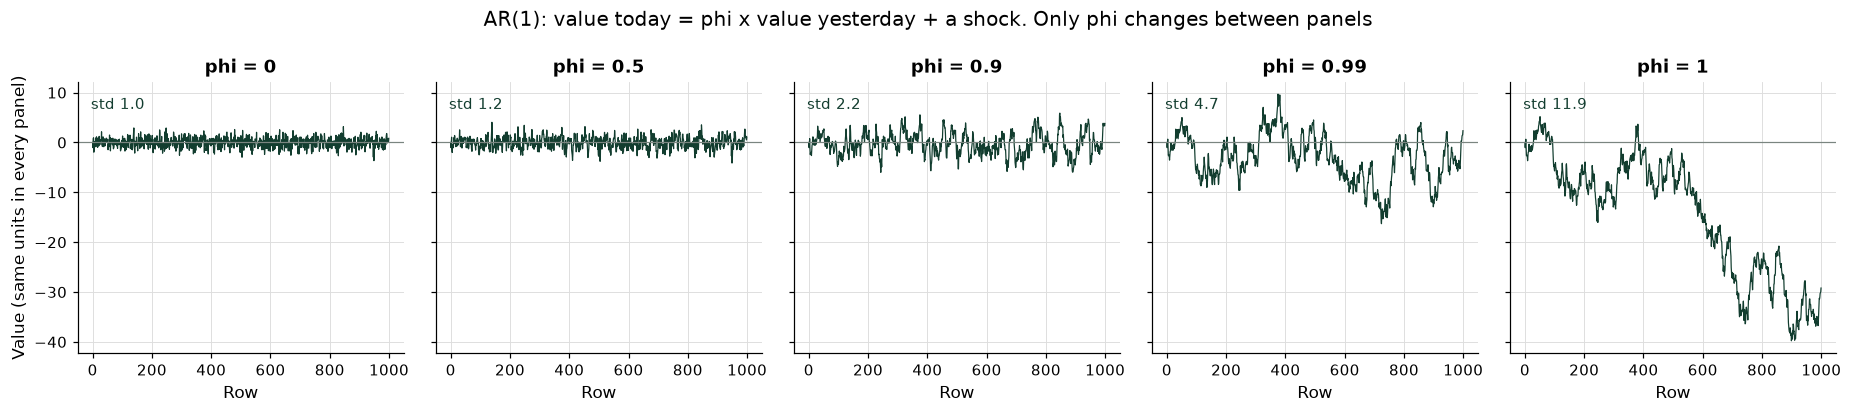

In [11]:
# the same 1,000 shocks through five values of phi, on one shared vertical scale
fig, axes = plt.subplots(1, 5, figsize=(17, 3.8), sharey=True)
for ax, phi in zip(axes, phis):
    ax.plot(simulated[phi], color=plotkit.GREEN_DARK, linewidth=0.8)
    ax.axhline(0, color=plotkit.GREY, linewidth=0.8)
    ax.set_title(f"phi = {phi:g}")
    ax.set_xlabel("Row")
    ax.text(0.04, 0.9, f"std {simulated[phi].std():.1f}", transform=ax.transAxes, fontsize=10, color=plotkit.GREEN_DARK)
axes[0].set_ylabel("Value (same units in every panel)")
fig.suptitle("AR(1): value today = phi x value yesterday + a shock. Only phi changes between panels")
fig.tight_layout()
plt.show()

* How to read it: the shocks are identical in every panel, so any difference is phi. At phi = 0 the series is the shocks: it hugs zero, with a standard deviation of 0.99. As phi rises, each shock lasts longer, and the standard deviation grows: 1.18, 2.23, 4.66. At phi = 1 the series is the running total of the shocks, and it ranges over 45 units against 7 for phi = 0.
* The last two panels look alike, and one is stationary. A series with phi = 0.99 is stationary on paper and behaves like a walk over 1,000 rows. That is why a test is needed, and why a test can be unsure at phi near 1.

Q. Table the spread and the average of each half. Is the average of the first half the average of the second?

In [12]:
plotkit.styled(spread_table, [], "The five simulated series: spread, range, and the mean of each half", fmt="{:.2f}")

,standard deviation,range,mean of first half,mean of second half
phi,,,,
0,0.99,6.83,-0.01,-0.04
0.5,1.18,8.18,-0.02,-0.10
0.9,2.23,11.88,-0.08,-0.57
0.99,4.66,25.99,-1.13,-5.18
1,11.93,44.95,-5.49,-24.03


* For phi up to 0.9 the two half-means sit near zero, as a stationary series' should. At phi = 1 they are -5.5 and -24.0: the average depends on when you look, which is what non-stationary means.

## 3.2 A Level and a Change, With a Trailing Window

Q. Draw the 10 Yr's level and its daily change, each with the mean of the 252 dates ending on each date, and the spread of the same window.

In [13]:
# a trailing window of 252 dates: the mean and the standard deviation of the 252 values ending on each date
window = 252
lv, ch = levels["10 Yr"], levels["10 Yr"].diff()
roll = pd.DataFrame({
    "level mean": lv.rolling(window).mean(), "level sd": lv.rolling(window).std(),
    "change mean": ch.rolling(window).mean(), "change sd": ch.rolling(window).std(),
}).dropna()
print(roll.agg(["min", "max"]).round(2).to_string())
print(f"the level's rolling mean moves {roll['level mean'].max() - roll['level mean'].min():.0f} bp; the change's, {roll['change mean'].max() - roll['change mean'].min():.2f} bp")
print(f"the change's rolling standard deviation: lowest {roll['change sd'].min():.2f} bp on {roll['change sd'].idxmin().date()}, highest {roll['change sd'].max():.2f} bp on {roll['change sd'].idxmax().date()}")

     level mean  level sd  change mean  change sd
min       81.60     10.87        -0.85       3.23
max      293.37     80.32         1.06       7.75
the level's rolling mean moves 212 bp; the change's, 1.91 bp
the change's rolling standard deviation: lowest 3.23 bp on 2018-05-21, highest 7.75 bp on 2022-12-30


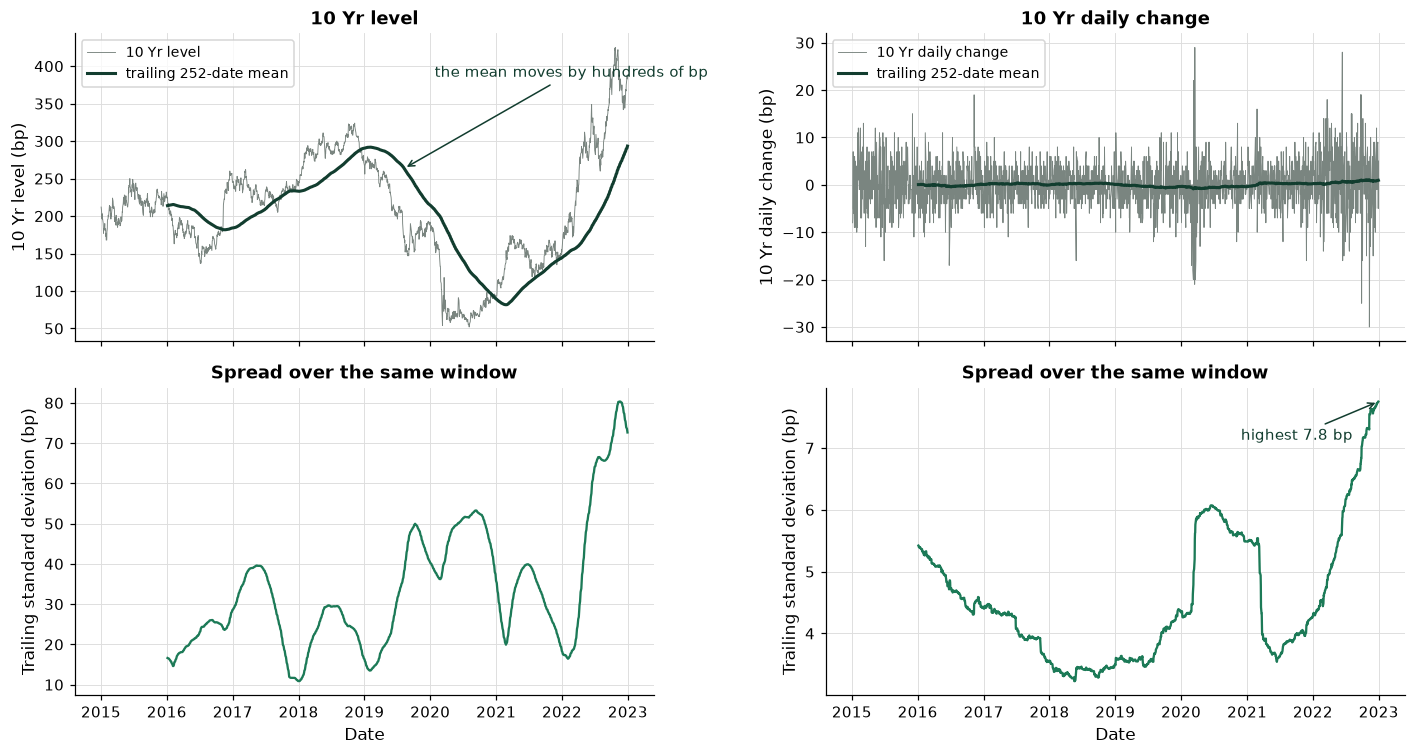

In [14]:
# top: the series with its trailing 252-date mean; bottom: its trailing 252-date standard deviation
fig, axes = plt.subplots(2, 2, figsize=(13, 7), sharex=True)
for column, (name, series, mean, sd, unit) in enumerate([
        ("10 Yr level", lv, roll["level mean"], roll["level sd"], "bp"),
        ("10 Yr daily change", ch, roll["change mean"], roll["change sd"], "bp")]):
    top, bottom = axes[0, column], axes[1, column]
    top.plot(series, color=plotkit.GREY, linewidth=0.6, label=name)
    top.plot(mean, color=plotkit.GREEN_DARK, linewidth=2, label="trailing 252-date mean")
    top.set_title(name)
    top.set_ylabel(f"{name} ({unit})")
    top.legend(loc="upper left", fontsize=9)
    bottom.plot(sd, color=plotkit.GREEN, linewidth=1.5)
    bottom.set_ylabel(f"Trailing standard deviation ({unit})")
    bottom.set_xlabel("Date")
    bottom.set_title("Spread over the same window")
axes[0, 0].annotate("the mean moves by hundreds of bp", xy=(roll.index[900], roll["level mean"].iloc[900]), xytext=(20, 60),
                    textcoords="offset points", fontsize=10, color=plotkit.GREEN_DARK, arrowprops={"arrowstyle": "->", "color": plotkit.GREEN_DARK})
axes[1, 1].annotate(f"highest {roll['change sd'].max():.1f} bp", xy=(roll["change sd"].idxmax(), roll["change sd"].max()),
                    xytext=(-90, -25), textcoords="offset points", fontsize=10, color=plotkit.GREEN_DARK,
                    arrowprops={"arrowstyle": "->", "color": plotkit.GREEN_DARK})
fig.tight_layout()
plt.show()

* The level's trailing mean moves by 212 bp over the development years: no single average describes it. The change's trailing mean moves by 1.9 bp, around zero.
* The change is not perfectly steady either: its trailing standard deviation ran from 3.23 bp (on 2018-05-21) to 7.75 bp (on 2022-12-30). A series can have a stable average and a spread that moves, and the tests below look mainly at the average. Day 7 is about the spread.
* A trailing window ends on the date it is drawn at, so it includes that date's own value. That is fine for a picture. If it were used as an input for scoring that date, it would need `shift(1)` first.

## 3.3 Testing: ADF and KPSS

**How it works (ADF).** The augmented Dickey-Fuller test asks whether yesterday's level pulls today's change back toward a level. It regresses the day's change on yesterday's level, a constant, and a few lagged changes that soak up memory. If the coefficient on yesterday's level is zero, there is no pull back: a unit root. If it is negative, the series is pulled back. The test statistic is that coefficient divided by its standard error, and it is compared with critical values that are more negative than a normal table's, because under a unit root the statistic does not follow a normal distribution. The null hypothesis is **a unit root**, so a small p-value (below 0.05) **rejects** it and says the series is stationary. You control the **regression** (a constant, a constant and a trend, or neither) and the **lags** (`maxlag`, and `autolag` to choose among them); what comes out is a statistic, a p-value, the lags used, and critical values.

Q. Write the first function of the day: `adf_summary`, with its private helper. Read the docstring first.

In [15]:
%%writefile -a tskit.py


import warnings  # kpss_summary names the one warning it handles

from statsmodels.tools.sm_exceptions import InterpolationWarning  # statsmodels' ADF and KPSS tests
from statsmodels.tsa.stattools import adfuller, kpss


def _values(series: pd.Series, name: str) -> np.ndarray:
    """The values of a Series as floats, or ValueError: a test needs at least 20 values and no blank."""
    if not isinstance(series, pd.Series):
        raise ValueError(f"{name} must be a pandas Series")
    values = series.to_numpy(dtype=float)
    if len(values) < 20:
        raise ValueError(f"{name} has {len(values)} values; a stationarity test needs at least 20")
    if np.isnan(values).any():
        raise ValueError(f"{name} has blank values: drop them first (the first change of a series is blank)")
    return values


def adf_summary(series: pd.Series, regression: str = "c", maxlag: int | None = None, autolag: str | None = "AIC") -> dict:
    """The augmented Dickey-Fuller test of a series, in a few named numbers.

    Null hypothesis: the series has a unit root (it wanders; it is not stationary). A small p-value rejects it.
    Inputs: series, values with no blank (levels or changes); regression, "c" (a constant), "ct" (a constant and a
    trend), or "n" (neither); maxlag, the most lagged changes to include (None lets statsmodels set it); autolag,
    the rule that picks the number of lagged changes up to maxlag ("AIC", "BIC", or None to use exactly maxlag).
    Output: a dict with statistic, p_value, lags_used, n_obs, critical_5pct (the 5 percent critical value), and
    rejects_unit_root (True when p_value is below 0.05).
    Raises ValueError for a series that is not a Series, has fewer than 20 values, or has a blank.
    """
    values = _values(series, "series")
    result = adfuller(values, maxlag=maxlag, regression=regression, autolag=autolag, result_object=True)
    return {"statistic": float(result.statistic), "p_value": float(result.pvalue), "lags_used": int(result.lags),
            "n_obs": int(result.nobs), "critical_5pct": float(result.critical_values["5%"]),
            "rejects_unit_root": bool(result.pvalue < 0.05)}

Appending to tskit.py


* The docstring says the null hypothesis in its second line, because the most common mistake with this test is to read its p-value the wrong way round. A **small** p-value means the series is stationary.
* `_values` is the private helper: it stops on anything but a Series, on fewer than 20 values, and on a blank, and the message says that the first change of a series is blank and must be dropped.
* `result_object=True` is passed every time: without it statsmodels 0.15 prints a `FutureWarning`, and a warning is a defect in this course.

Q. Write the tests: a seeded random walk and seeded white noise, and the statistic computed by hand.

In [16]:
%%writefile -a test_tskit.py


def walk_and_noise() -> tuple[pd.Series, pd.Series]:
    """A seeded random walk and seeded white noise, 500 values each."""
    rng = np.random.default_rng(42)
    noise = pd.Series(rng.standard_normal(500))
    return noise.cumsum(), noise


def test_adf_summary_walk_and_noise():
    walk, noise = walk_and_noise()
    on_walk, on_noise = tskit.adf_summary(walk), tskit.adf_summary(noise)
    # a random walk has a unit root: the test does not reject it; noise does not: the test rejects
    assert not on_walk["rejects_unit_root"] and on_walk["p_value"] > 0.05
    assert on_noise["rejects_unit_root"] and on_noise["p_value"] < 0.001
    assert on_walk["statistic"] > on_walk["critical_5pct"] and on_noise["statistic"] < on_noise["critical_5pct"]


def test_adf_with_no_lags_is_a_regression():
    walk, _ = walk_and_noise()
    summary = tskit.adf_summary(walk, regression="c", maxlag=0, autolag=None)
    # the change on its lagged level and a constant: the statistic is the slope divided by its standard error
    y = walk.to_numpy()
    X = np.column_stack([np.ones(len(y) - 1), y[:-1]])
    target = np.diff(y)
    beta, *_ = np.linalg.lstsq(X, target, rcond=None)
    resid = target - X @ beta
    se = np.sqrt(resid @ resid / (len(target) - 2) * np.linalg.inv(X.T @ X)[1, 1])
    assert summary["statistic"] == pytest.approx(beta[1] / se)
    assert summary["lags_used"] == 0 and summary["n_obs"] == len(target)

Appending to test_tskit.py


* `test_adf_with_no_lags_is_a_regression` computes the statistic with `numpy` alone: regress the change on a constant and the lagged level, and divide the slope by its standard error. It equals `adf_summary` with no lagged changes, so the test is not magic: it is a regression and a table.

Q. Reload the modules and run the tests.

In [17]:
# the files changed, so reload before using the new function
importlib.reload(tskit)
print(f"adf_summary in tskit: {hasattr(tskit, 'adf_summary')}")

adf_summary in tskit: True


In [18]:
# run the tests in the work folder with the kernel's own Python, in a fresh process
result = subprocess.run([sys.executable, "-m", "pytest", "-q", "-p", "no:cacheprovider", "test_tskit.py"],
                        cwd=work, capture_output=True, text=True)
print(result.stdout + result.stderr)

................                                                         [100%]
16 passed in 2.30s



* `16 passed`: day 2's 14 and two new ones.

Q. Read every setting of `adfuller`, with the defaults taken from the installed statsmodels.

In [19]:
import inspect

from statsmodels.tsa.stattools import adfuller

# the defaults are read from the installed statsmodels, never typed
defaults = {name: parameter.default for name, parameter in inspect.signature(adfuller).parameters.items()}
adf_settings = pd.DataFrame([
    ("regression", defaults["regression"], "what the test regression holds besides the lagged level: c a constant, ct a constant and a trend, n neither",
     "ct asks for stationary around a trend; n assumes the series is centred on zero", "yes"),
    ("maxlag", defaults["maxlag"], "the most lagged changes added to absorb memory in the changes (None: 12 x (n / 100) to the power 0.25)",
     "more lags soak up more memory and cost observations and power", "yes"),
    ("autolag", defaults["autolag"], "how the number of lagged changes is chosen up to maxlag: AIC, BIC, or None to use exactly maxlag",
     "None with maxlag set fixes the lags; AIC tends to pick more lags than BIC", "yes"),
    ("store", defaults["store"], "True returns the regression's pieces too", "no effect on the test", "no"),
    ("regresults", defaults["regresults"], "True returns the full regression of the test", "no effect on the test", "no"),
    ("result_object", defaults["result_object"], "True returns a result object; None warns that the return type will change",
     "always pass True, which course code does", "no"),
], columns=["setting", "default", "what it controls", "raising it", "tune first"]).set_index("setting")
adf_settings["default"] = adf_settings["default"].map(repr)

plotkit.styled(adf_settings, [], "Every setting of adfuller: the defaults read from the installed statsmodels")

,default,what it controls,raising it,tune first
setting,,,,
regression,'c',"what the test regression holds besides the lagged level: c a constant, ct a constant and a trend, n neither",ct asks for stationary around a trend; n assumes the series is centred on zero,yes
maxlag,None,the most lagged changes added to absorb memory in the changes (None: 12 x (n / 100) to the power 0.25),more lags soak up more memory and cost observations and power,yes
autolag,'AIC',"how the number of lagged changes is chosen up to maxlag: AIC, BIC, or None to use exactly maxlag",None with maxlag set fixes the lags; AIC tends to pick more lags than BIC,yes
store,False,True returns the regression's pieces too,no effect on the test,no
regresults,False,True returns the full regression of the test,no effect on the test,no
result_object,None,True returns a result object; None warns that the return type will change,"always pass True, which course code does",no


* Two settings matter, marked "tune first": the `regression` and the lags (`maxlag` with `autolag`). The rest are housekeeping. Section 3.3's sweep, below, shows what each does.

**How it works (KPSS).** The KPSS test turns the question round: its null hypothesis is that the series **is stationary**. It takes the series' average away (or its trend), adds up what is left as a running total, and compares the size of that running total with what a stationary series would give. A stationary series' deviations cancel out, so the running total stays small; a wandering series' deviations pile up, so it ranges far, the statistic is large, and the null is **rejected**. You control the regression (`c` for around a constant, `ct` for around a trend) and `nlags`, the lags in the estimate of the series' long-run variance; what comes out is a statistic, a p-value read from a table that runs only from 0.01 to 0.1, and critical values. So a **small** KPSS p-value says the series is **not** stationary: the opposite reading of ADF's.

Q. Add `kpss_summary`.

In [20]:
%%writefile -a tskit.py


def kpss_summary(series: pd.Series, regression: str = "c", nlags: str | int = "auto") -> dict:
    """The KPSS test of a series, in a few named numbers.

    Null hypothesis: the series is stationary (around a constant for "c", around a trend for "ct"). A small p-value
    rejects it, which is the opposite reading of the ADF test.
    Inputs: series, values with no blank; regression, "c" or "ct"; nlags, "auto" or the number of lags in the
    long-run variance estimate.
    Output: a dict with statistic, p_value, lags_used, critical_5pct, p_note, and rejects_stationarity (True when
    p_value is below 0.05). statsmodels interpolates p-values in a table that runs from 0.01 to 0.1, so a statistic
    outside the table gives 0.01 or 0.1 exactly; p_note then says "at most 0.01" or "at least 0.1", and "inside the
    table" otherwise.
    Raises ValueError for a series that is not a Series, has fewer than 20 values, or has a blank.
    """
    values = _values(series, "series")
    # statsmodels warns when the statistic is outside its p-value table; p_note carries that information instead
    with warnings.catch_warnings():
        warnings.simplefilter("ignore", InterpolationWarning)
        result = kpss(values, regression=regression, nlags=nlags, result_object=True)
    p_value = float(result.pvalue)
    note = "at most 0.01" if p_value <= 0.01 else "at least 0.1" if p_value >= 0.1 else "inside the table"
    return {"statistic": float(result.statistic), "p_value": p_value, "lags_used": int(result.lags),
            "critical_5pct": float(result.critical_values["5%"]), "p_note": note, "rejects_stationarity": bool(p_value < 0.05)}

Appending to tskit.py


* Because the table stops at 0.01 and 0.1, a statistic outside it gives exactly 0.01 or 0.1. statsmodels warns about that every time; the function handles the warning once, in the module, and reports it instead in `p_note` ("at most 0.01", "at least 0.1", "inside the table"). A reader then knows that a KPSS p of 0.01 means "0.01 or smaller".

Q. Add its tests, reload, and run pytest.

In [21]:
%%writefile -a test_tskit.py


def test_kpss_summary_reads_the_other_way():
    walk, noise = walk_and_noise()
    on_walk, on_noise = tskit.kpss_summary(walk), tskit.kpss_summary(noise)
    # KPSS rejects stationarity for the walk and does not for the noise, the reverse of ADF's reading
    assert on_walk["rejects_stationarity"] and not on_noise["rejects_stationarity"]
    assert on_walk["p_note"] in ("at most 0.01", "inside the table") and on_noise["p_note"] == "at least 0.1"
    assert on_noise["p_value"] == 0.1


def test_summaries_refuse_bad_input():
    walk, _ = walk_and_noise()
    blank = walk.copy()
    blank.iloc[3] = np.nan
    for function in (tskit.adf_summary, tskit.kpss_summary):
        with pytest.raises(ValueError, match="blank"):
            function(blank)
        with pytest.raises(ValueError, match="at least 20"):
            function(walk.iloc[:10])
        with pytest.raises(ValueError, match="Series"):
            function(walk.to_numpy())

Appending to test_tskit.py


In [22]:
# the files changed, so reload before using the new function
importlib.reload(tskit)
print(f"kpss_summary in tskit: {hasattr(tskit, 'kpss_summary')}")

kpss_summary in tskit: True


In [23]:
# run the tests in the work folder with the kernel's own Python, in a fresh process
result = subprocess.run([sys.executable, "-m", "pytest", "-q", "-p", "no:cacheprovider", "test_tskit.py"],
                        cwd=work, capture_output=True, text=True)
print(result.stdout + result.stderr)

..................                                                       [100%]
18 passed in 2.26s



* `18 passed`. The KPSS test rejects the walk and not the noise, the reverse of ADF.

Q. Read every setting of `kpss`.

In [24]:
import inspect

from statsmodels.tsa.stattools import kpss

kpss_defaults = {name: parameter.default for name, parameter in inspect.signature(kpss).parameters.items()}
kpss_settings = pd.DataFrame([
    ("regression", kpss_defaults["regression"], "c tests stationarity around a constant; ct around a trend",
     "ct tolerates a steady drift in the level", "yes"),
    ("nlags", kpss_defaults["nlags"], "the lags in the long-run variance: auto picks from the sample size, legacy uses a fixed rule, or give an integer",
     "more lags lower the statistic and make rejection harder", "yes"),
    ("store", kpss_defaults["store"], "True returns the pieces of the test too", "no effect on the test", "no"),
    ("result_object", kpss_defaults["result_object"], "True returns a result object; None warns that the return type will change",
     "always pass True, which course code does", "no"),
], columns=["setting", "default", "what it controls", "raising it", "tune first"]).set_index("setting")
kpss_settings["default"] = kpss_settings["default"].map(repr)

# nlags swept on the 10 Yr's level and change: the statistic falls as lags are added; 0.463 is the 5 percent critical value
kpss_rows = []
for nlags in [0, 5, 10, 20, 40]:
    kpss_rows.append({"nlags": nlags,
                      "10 Yr levels": tskit.kpss_summary(levels["10 Yr"], nlags=nlags)["statistic"],
                      "10 Yr changes": tskit.kpss_summary(levels["10 Yr"].diff().dropna(), nlags=nlags)["statistic"]})
kpss_sweep = pd.DataFrame(kpss_rows).set_index("nlags")
kpss_critical = tskit.kpss_summary(levels["10 Yr"])["critical_5pct"]
print(kpss_sweep.round(3).to_string())
print(f"5 percent critical value: {kpss_critical}")

plotkit.styled(kpss_settings, [], "Every setting of kpss: the defaults read from the installed statsmodels")

       10 Yr levels  10 Yr changes
nlags                             
0            17.833          0.334
5             2.994          0.358
10            1.643          0.352
20            0.870          0.329
40            0.457          0.301
5 percent critical value: 0.463


,default,what it controls,raising it,tune first
setting,,,,
regression,'c',c tests stationarity around a constant; ct around a trend,ct tolerates a steady drift in the level,yes
nlags,'auto',"the lags in the long-run variance: auto picks from the sample size, legacy uses a fixed rule, or give an integer",more lags lower the statistic and make rejection harder,yes
store,False,True returns the pieces of the test too,no effect on the test,no
result_object,None,True returns a result object; None warns that the return type will change,"always pass True, which course code does",no


* `nlags="auto"` chose 28 lags for the 10 Yr's level, with a statistic of 0.64 against a 5 percent critical value of 0.463.

Q. Run both tests on the five simulated series, whose phi we know.

In [25]:
# both tests on the five simulated series, whose truth we know
rows = []
for phi, series in simulated.items():
    adf, kp = tskit.adf_summary(series), tskit.kpss_summary(series)
    rows.append({"phi": phi, "ADF p-value": adf["p_value"], "ADF rejects a unit root": adf["rejects_unit_root"],
                 "KPSS p-value": kp["p_value"], "KPSS rejects stationarity": kp["rejects_stationarity"], "KPSS p-value is": kp["p_note"]})
sim_tests = pd.DataFrame(rows).set_index("phi")
print(sim_tests.to_string())

plotkit.styled(sim_tests, [], "ADF and KPSS on the five simulated series: a small ADF p-value and a large KPSS p-value mean stationary", fmt="{:.4f}")

       ADF p-value  ADF rejects a unit root  KPSS p-value  KPSS rejects stationarity KPSS p-value is
phi                                                                                                 
0.00  0.000000e+00                     True          0.10                      False    at least 0.1
0.50  4.238798e-29                     True          0.10                      False    at least 0.1
0.90  6.339717e-12                     True          0.10                      False    at least 0.1
0.99  5.349312e-03                     True          0.01                       True    at most 0.01
1.00  5.787132e-01                    False          0.01                       True    at most 0.01


,ADF p-value,ADF rejects a unit root,KPSS p-value,KPSS rejects stationarity,KPSS p-value is
phi,,,,,
0,0.0000,True,0.1000,False,at least 0.1
0.5,0.0000,True,0.1000,False,at least 0.1
0.9,0.0000,True,0.1000,False,at least 0.1
0.99,0.0053,True,0.0100,True,at most 0.01
1,0.5787,False,0.0100,True,at most 0.01


* ADF rejects a unit root for phi up to 0.99 and not for phi = 1. KPSS does not reject stationarity up to 0.9, and rejects at 0.99 and 1. So at **phi = 0.99** the two tests disagree: ADF's p-value is 0.0053, and KPSS says not stationary. A series that is stationary on paper and wanders in practice is exactly where the two tests part, and why a decision uses both. At phi = 1, ADF's p-value is 0.58: no evidence against the unit root.
* The KPSS p-values are 0.1 or 0.01 exactly: the table's ends, with `p_note` saying so.

Q. Sweep the settings that matter on the real series: the `regression`, and `maxlag`, on the 10 Yr's level, the HY spread's level, and the 10 Yr's change.

In [26]:
# the two settings marked "tune first", swept on the series where they matter: regression, then the number of lagged changes
regression_rows = []
for regression in ["c", "ct", "n"]:
    regression_rows.append({"regression": regression} | {
        f"{name} {form}": tskit.adf_summary(series, regression=regression)["p_value"]
        for name, form, series in (("10 Yr", "levels", levels["10 Yr"]), ("HY", "levels", levels["HY"]),
                                   ("10 Yr", "changes", levels["10 Yr"].diff().dropna()))})
regression_sweep = pd.DataFrame(regression_rows).set_index("regression")
print(regression_sweep.to_string())

lag_rows = []
for maxlag in [0, 1, 5, 10, 20, 40]:
    lag_rows.append({"maxlag": maxlag} | {
        f"{name} {form}": tskit.adf_summary(series, maxlag=maxlag, autolag=None)["p_value"]
        for name, form, series in (("10 Yr", "levels", levels["10 Yr"]), ("HY", "levels", levels["HY"]),
                                   ("10 Yr", "changes", levels["10 Yr"].diff().dropna()))})
lag_sweep = pd.DataFrame(lag_rows).set_index("maxlag")
print(lag_sweep.round(4).to_string())

plotkit.styled(regression_sweep, [], "ADF p-value by regression setting, development years", fmt="{:.4f}")

            10 Yr levels  HY levels  10 Yr changes
regression                                        
c               0.869911   0.079262   2.089351e-24
ct              0.982098   0.115405   9.874634e-21
n               0.858350   0.697293   9.750871e-24
        10 Yr levels  HY levels  10 Yr changes
maxlag                                        
0             0.8828     0.0793            0.0
1             0.8868     0.0711            0.0
5             0.9007     0.0923            0.0
10            0.8699     0.1131            0.0
20            0.7956     0.2558            0.0
40            0.8549     0.3321            0.0


,10 Yr levels,HY levels,10 Yr changes
regression,,,
c,0.8699,0.0793,0.0000
ct,0.9821,0.1154,0.0000
n,0.8583,0.6973,0.0000


In [27]:
plotkit.styled(lag_sweep, [], "ADF p-value by maxlag (autolag off), development years", fmt="{:.4f}")

,10 Yr levels,HY levels,10 Yr changes
maxlag,,,
0,0.8828,0.0793,0.0000
1,0.8868,0.0711,0.0000
5,0.9007,0.0923,0.0000
10,0.8699,0.1131,0.0000
20,0.7956,0.2558,0.0000
40,0.8549,0.3321,0.0000


Q. Draw the sweeps: the ADF p-value as `maxlag` grows, and by `regression`, and the KPSS statistic as `nlags` grows.

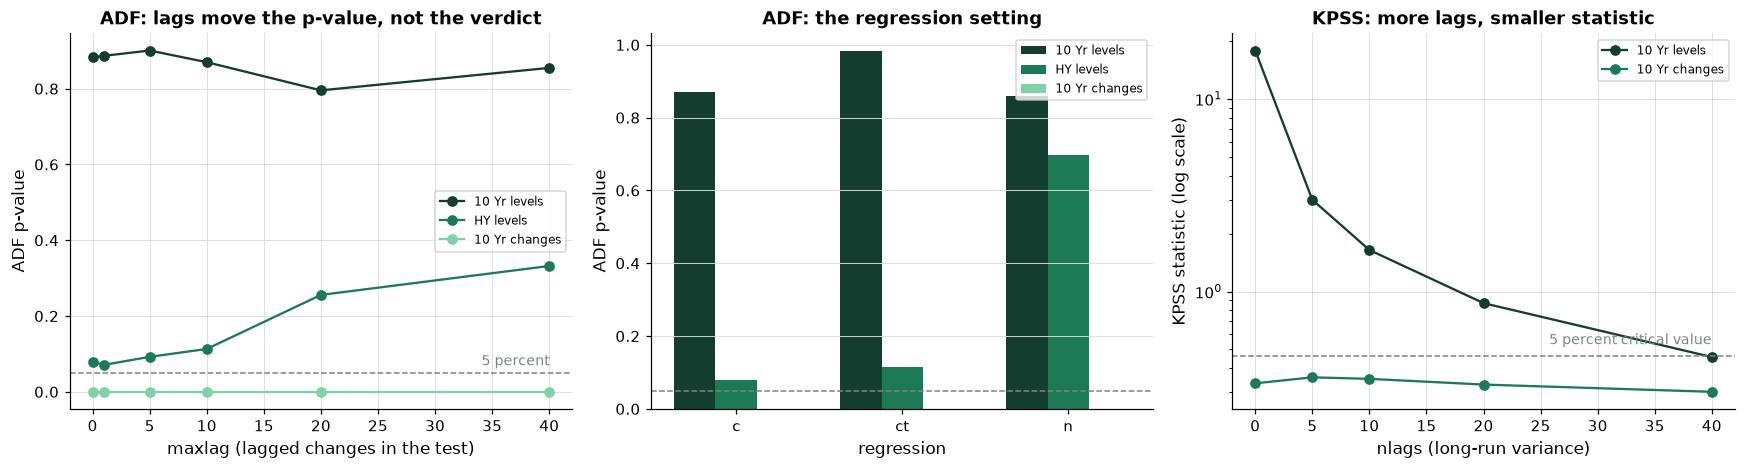

In [28]:
# left: the ADF p-value as maxlag grows; middle: by regression; right: the KPSS statistic as nlags grows
fig, (left, middle, right) = plt.subplots(1, 3, figsize=(16, 4.4))
for column in lag_sweep.columns:
    left.plot(lag_sweep.index, lag_sweep[column], marker="o", label=column)
left.axhline(0.05, color=plotkit.GREY, linestyle="--", linewidth=1)
left.text(lag_sweep.index.max(), 0.07, "5 percent", ha="right", fontsize=9, color=plotkit.GREY)
left.set_xlabel("maxlag (lagged changes in the test)")
left.set_ylabel("ADF p-value")
left.set_title("ADF: lags move the p-value, not the verdict")
left.legend(fontsize=8, loc="center right")
width = 0.25
for number, column in enumerate(regression_sweep.columns):
    middle.bar(np.arange(3) + (number - 1) * width, regression_sweep[column], width, label=column)
middle.axhline(0.05, color=plotkit.GREY, linestyle="--", linewidth=1)
middle.set_xticks(np.arange(3), ["c", "ct", "n"])
middle.set_xlabel("regression")
middle.set_ylabel("ADF p-value")
middle.set_title("ADF: the regression setting")
middle.legend(fontsize=8, loc="upper right")
middle.grid(axis="x", visible=False)
for column in kpss_sweep.columns:
    right.plot(kpss_sweep.index, kpss_sweep[column], marker="o", label=column)
right.axhline(kpss_critical, color=plotkit.GREY, linestyle="--", linewidth=1)
right.set_yscale("log")
right.text(kpss_sweep.index.max(), kpss_critical * 1.15, "5 percent critical value", ha="right", fontsize=9, color=plotkit.GREY)
right.set_xlabel("nlags (long-run variance)")
right.set_ylabel("KPSS statistic (log scale)")
right.set_title("KPSS: more lags, smaller statistic")
right.legend(fontsize=8)
fig.tight_layout()
plt.show()

* How to read it. **Left:** the 10 Yr's level stays far above the 5 percent line at every `maxlag` (its p-value runs from 0.80 to 0.90), and its change sits at zero at every one: the verdict does not depend on the lag. The HY level is the exception worth noticing: its p-value is 0.079 with no lagged changes and 0.33 with 40, so it is close to the line and moves with the setting; `autolag="AIC"` chose 0 lags for it. **Middle:** a trend in the regression (`ct`) does not rescue the levels: the 10 Yr's p-value goes to 0.98, so these levels do not wander around a straight trend either. **Right:** the KPSS statistic falls steeply as lags are added, from 17.8 with none to 0.46 with 40, which is under the critical value of 0.463: a long enough lag window can hide a wandering series. The change's statistic never leaves 0.30 to 0.36. **Choose the settings from the series and say so; never from the one that gives the answer you wanted.** The course uses the defaults, `autolag="AIC"` and `nlags="auto"`, and shows this picture so the choice is visible.

Q. Run both tests on every series, in levels and in changes, and read each pair with the table of four readings.

In [29]:
# the four readings of an ADF and a KPSS test together
reading = pd.DataFrame({
    "ADF (null: a unit root)": ["rejects", "does not reject", "rejects", "does not reject"],
    "KPSS (null: stationary)": ["does not reject", "rejects", "rejects", "does not reject"],
    "Reading": ["stationary", "a unit root", "stationary around shifts in mean or variance", "not enough evidence either way"],
    "What to do": ["fit on it as it is", "difference it, then test again", "find the shift: a break, a drift, or a change in spread",
                   "more data, or a different regression setting"],
}, index=pd.Index(["1", "2", "3", "4"], name="Case"))

plotkit.styled(reading, [], "Reading an ADF test and a KPSS test together: the four cases")

,ADF (null: a unit root),KPSS (null: stationary),Reading,What to do
Case,,,,
1,rejects,does not reject,stationary,fit on it as it is
2,does not reject,rejects,a unit root,"difference it, then test again"
3,rejects,rejects,stationary around shifts in mean or variance,"find the shift: a break, a drift, or a change in spread"
4,does not reject,does not reject,not enough evidence either way,"more data, or a different regression setting"


In [30]:
# both tests on each series in levels and in changes, and what the pair says (the table above gives the four readings)
verdicts = {
    (True, False): "stationary",
    (False, True): "unit root: difference it",
    (True, True): "both reject: look for a shift in mean or variance",
    (False, False): "inconclusive: neither rejects",
}
rows = []
for column in levels.columns:
    for form, series in (("levels", levels[column]), ("changes", levels[column].diff().dropna())):
        adf, kp = tskit.adf_summary(series), tskit.kpss_summary(series)
        rows.append({"series": column, "form": form, "ADF p-value": adf["p_value"], "KPSS p-value": kp["p_value"],
                     "KPSS p-value is": kp["p_note"], "lags used": adf["lags_used"],
                     "reading": verdicts[(adf["rejects_unit_root"], kp["rejects_stationarity"])]})
real_tests = pd.DataFrame(rows).set_index(["series", "form"])
print(real_tests.to_string())

plotkit.styled(real_tests, [], "ADF and KPSS on the five series, levels and changes, development years: p-values and the reading", fmt="{:.4f}")

                 ADF p-value  KPSS p-value   KPSS p-value is  lags used                                            reading
series form                                                                                                               
2 Yr   levels   9.779276e-01      0.010000      at most 0.01         19                           unit root: difference it
       changes  2.569658e-12      0.010000      at most 0.01         18  both reject: look for a shift in mean or variance
10 Yr  levels   8.699105e-01      0.019362  inside the table         10                           unit root: difference it
       changes  2.089351e-24      0.100000      at least 0.1          9                                         stationary
2s10s  levels   7.879405e-01      0.010000      at most 0.01         22                           unit root: difference it
       changes  1.003564e-12      0.100000      at least 0.1         22                                         stationary
IG     levels   

<styled table: ADF and KPSS on the five series, levels and changes, development years: p-values and the reading>

* **Levels:** all five are read as a unit root: ADF does not reject (p from 0.079 for the HY spread to 0.978 for the 2 Yr) and KPSS rejects. Differencing them is the standard step.
* **Changes:** four of five read as stationary: ADF rejects at once (p is zero to four decimals) and KPSS does not reject. This is the evidence for working with changes in this course.
* **The exception is the 2 Yr's changes**, where **both** tests reject, case 3 of the table: ADF says there is no unit root, and KPSS says the series is not stationary around a constant. The two statements fit together when the average or the spread moves with the years, as the next cell shows.

Q. Why do the 2 Yr's changes fail KPSS? Take the mean and the standard deviation of its daily change in each year.

In [31]:
# why the 2 Yr's changes fail KPSS: their mean and spread are not the same in every year
by_year = levels["2 Yr"].diff().dropna().groupby(levels["2 Yr"].index[1:].year).agg(["mean", "std"])
by_year.columns = ["mean change (bp)", "standard deviation (bp)"]
by_year.index.name = "year"
print(by_year.round(2).to_string())

plotkit.styled(by_year, [], "The 2 Yr's daily change by year, in bp", fmt="{:.2f}")

      mean change (bp)  standard deviation (bp)
year                                           
2015              0.16                     3.40
2016              0.06                     3.35
2017              0.28                     2.54
2018              0.24                     2.96
2019             -0.36                     4.47
2020             -0.58                     3.33
2021              0.24                     2.35
2022              1.48                     8.00


,mean change (bp),standard deviation (bp)
year,,
2015,0.16,3.40
2016,0.06,3.35
2017,0.28,2.54
2018,0.24,2.96
2019,-0.36,4.47
2020,-0.58,3.33
2021,0.24,2.35
2022,1.48,8.00


* In 2022 the 2 Yr's change had a mean of 1.48 bp a day and a standard deviation of 8.00 bp. In the earlier years the mean was between -0.58 and 0.28 bp and the standard deviation between 2.35 and 4.47. One year is unlike the others. A test that assumes one constant average and one spread over eight years sees that, and a model fitted on 2015 to 2021 would be asked to describe 2022. **A unit root removed is not the same as a series that behaves the same in every year.** Day 7 returns to the spread.

## 3.4 The Spurious Regression

**How it works.** A regression of one series on another measures how well a straight line explains the first from the second. For two stationary series that are unrelated, the R-squared is near zero, as it should be. For two series that **wander**, it is not: each is a running total of its own shocks, so over any stretch each drifts up or down, and a stretch in which both drift the same way looks like a relationship. The R-squared is then high, the slope is "significant", and the residuals are one long wander, which a Durbin-Watson statistic near 0 gives away. The fix is to regress changes on changes, or to test for a relationship that survives differencing, which day 9's cointegration does. You control nothing here but the data; what comes out is a regression that should not be trusted.

Q. Draw 1,000 pairs of independent random walks and 1,000 pairs of white noise, and take the R-squared of each pair. Then run one regression in detail.

In [32]:
# 1,000 pairs of independent series of 500 values: random walks, and white noise. R-squared of one on the other.
rng = np.random.default_rng(SEED)
shocks_ab = rng.standard_normal((1_000, 2, 500))
walks = shocks_ab.cumsum(axis=2)


def r_squared(a, b):
    """The squared correlation of two arrays: the R-squared of a regression of one on the other."""
    return float(np.corrcoef(a, b)[0, 1] ** 2)


r2_walks = np.array([r_squared(pair[0], pair[1]) for pair in walks])
r2_noise = np.array([r_squared(pair[0], pair[1]) for pair in shocks_ab])
print(f"independent random walks: median R-squared {np.median(r2_walks):.3f}; share of pairs above 0.3: {(r2_walks > 0.3).mean():.1%}")
print(f"independent white noise:  median R-squared {np.median(r2_noise):.4f}; share of pairs above 0.3: {(r2_noise > 0.3).mean():.1%}")

# one pair: the slope, R-squared, and Durbin-Watson (about 2 for a good fit, near 0 when the residuals are one long wander)
x, y = walks[0]
slope, intercept = np.polyfit(x, y, 1)
residual = y - (slope * x + intercept)
durbin_watson = float((np.diff(residual) ** 2).sum() / (residual ** 2).sum())
print(f"first pair: slope {slope:.2f}, R-squared {r_squared(x, y):.3f}, Durbin-Watson {durbin_watson:.3f}")

independent random walks: median R-squared 0.182; share of pairs above 0.3: 37.7%
independent white noise:  median R-squared 0.0010; share of pairs above 0.3: 0.0%
first pair: slope 0.94, R-squared 0.200, Durbin-Watson 0.025


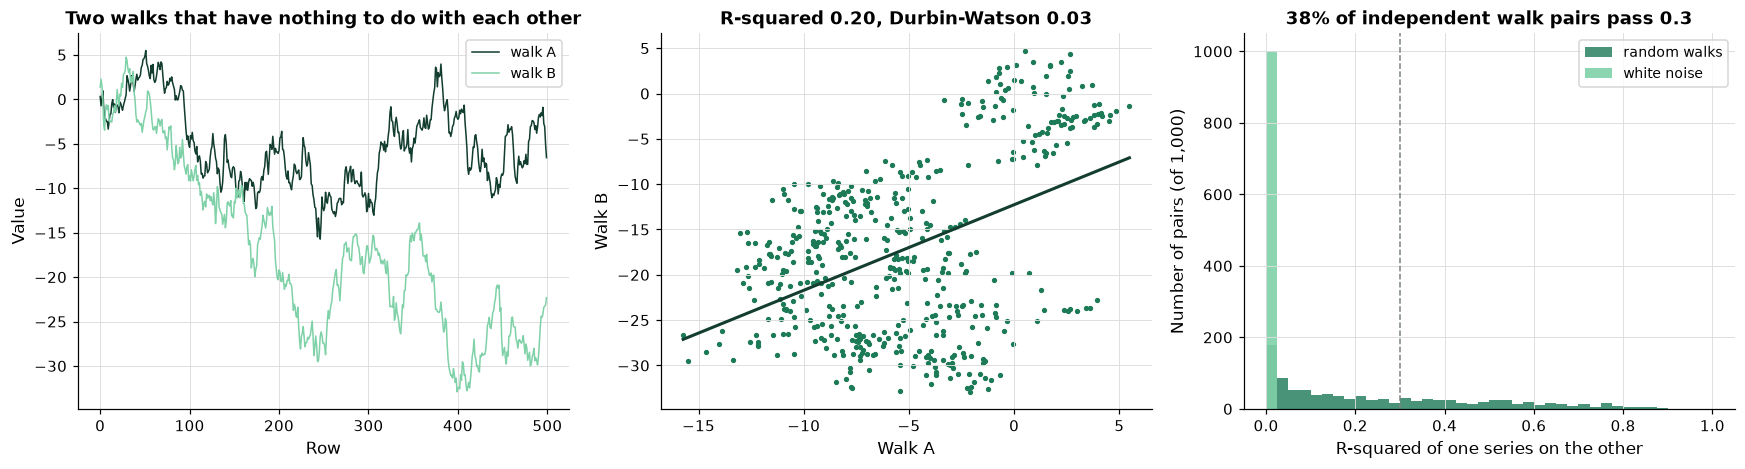

In [33]:
# left: one pair of independent random walks; middle: one against the other; right: R-squared over 1,000 pairs
fig, (left, middle, right) = plt.subplots(1, 3, figsize=(16, 4.4))
x, y = walks[0]
left.plot(x, color=plotkit.GREEN_DARK, linewidth=1, label="walk A")
left.plot(y, color=plotkit.GREEN_LIGHT, linewidth=1, label="walk B")
left.set_xlabel("Row")
left.set_ylabel("Value")
left.set_title("Two walks that have nothing to do with each other")
left.legend(fontsize=9)
middle.scatter(x, y, s=6, color=plotkit.GREEN)
middle.plot(np.sort(x), slope * np.sort(x) + intercept, color=plotkit.GREEN_DARK, linewidth=2)
middle.set_xlabel("Walk A")
middle.set_ylabel("Walk B")
middle.set_title(f"R-squared {r_squared(x, y):.2f}, Durbin-Watson {durbin_watson:.2f}")
bins = np.linspace(0, 1, 41)
right.hist(r2_walks, bins=bins, color=plotkit.GREEN, alpha=0.8, label="random walks")
right.hist(r2_noise, bins=bins, color=plotkit.GREEN_LIGHT, alpha=0.9, label="white noise")
right.axvline(0.3, color=plotkit.GREY, linestyle="--", linewidth=1)
right.set_xlabel("R-squared of one series on the other")
right.set_ylabel("Number of pairs (of 1,000)")
right.set_title(f"{(r2_walks > 0.3).mean():.0%} of independent walk pairs pass 0.3")
right.legend(fontsize=9)
fig.tight_layout()
plt.show()

* How to read it. **Left and middle:** two walks that were generated with no link at all, and a line through their scatter with an R-squared of 0.20. The Durbin-Watson statistic is 0.025: the residuals are one long wander, not noise. **Right:** across 1,000 pairs, independent random walks have a median R-squared of 0.18, and 37.7% of pairs pass 0.3. Independent noise has a median of 0.0010 and no pair passes 0.3.

Q. The same on real data: the 10 Yr's level on the invented spreads' levels, and then their changes. The spreads were generated without reference to yields.

In [34]:
# the same on real data: the 10 Yr's level on the invented spreads' levels, and then their changes
ten = levels["10 Yr"]
r2_real = pd.DataFrame({
    "R-squared of the levels": [r_squared(ten, levels[other]) for other in ["IG", "HY"]],
    "R-squared of the changes": [r_squared(ten.diff().dropna(), levels[other].diff().dropna()) for other in ["IG", "HY"]],
}, index=pd.Index(["IG spread", "HY spread"], name="10 Yr against"))
print(r2_real.round(4).to_string())

plotkit.styled(r2_real, [], "R-squared of the 10 Yr on each invented spread: levels and changes, development years", fmt="{:.4f}")

               R-squared of the levels  R-squared of the changes
10 Yr against                                                   
IG spread                       0.1389                    0.0001
HY spread                       0.0662                    0.0002


,R-squared of the levels,R-squared of the changes
10 Yr against,,
IG spread,0.1389,0.0001
HY spread,0.0662,0.0002


* The 10 Yr's level explains 13.9% of the invented IG spread's level, and its changes explain 0.01% of the IG spread's changes. The generator never linked the two, so the first number is the spurious regression on real yields, and the second is the truth. **A high R-squared between two levels is not evidence of a relationship.**

## 3.5 Differencing, and When a Log Helps

**How it works.** A series with a unit root is a running total of stationary shocks, so taking each value less the one before it, a **first difference**, undoes the running total and leaves the shocks. You control how many times to difference (the order, `d`) and whether to take logs first. For the yield and spread levels here one difference is enough, as the tests above showed. A second difference of a series that is already stationary is **over-differencing**: it subtracts a value that was already a shock, so it adds noise and puts a negative correlation of about -0.5 between neighbours. A **log** helps when a series compounds, so that its moves grow with its level and the changes in points get bigger as it rises; a change in logs is a percentage move, which does not. What comes out of differencing is a series one value shorter per difference, in the unit of the input (bp) or in log points.

Q. Difference the 10 Yr once and twice. Is the second difference stationary, and what has it done to the spread and the autocorrelation?

In [35]:
# first and second differences of the 10 Yr: the second looks stationary too, and adds noise
first = levels["10 Yr"].diff().dropna()
second = first.diff().dropna()
print(f"standard deviation: first difference {first.std():.2f} bp, second difference {second.std():.2f} bp")
print(f"lag-1 autocorrelation: first difference {first.autocorr(1):.3f}, second difference {second.autocorr(1):.3f}")
print(f"ADF p-value of the second difference: {tskit.adf_summary(second)['p_value']:.1e}")

standard deviation: first difference 5.03 bp, second difference 7.14 bp
lag-1 autocorrelation: first difference -0.007, second difference -0.485
ADF p-value of the second difference: 1.6e-28


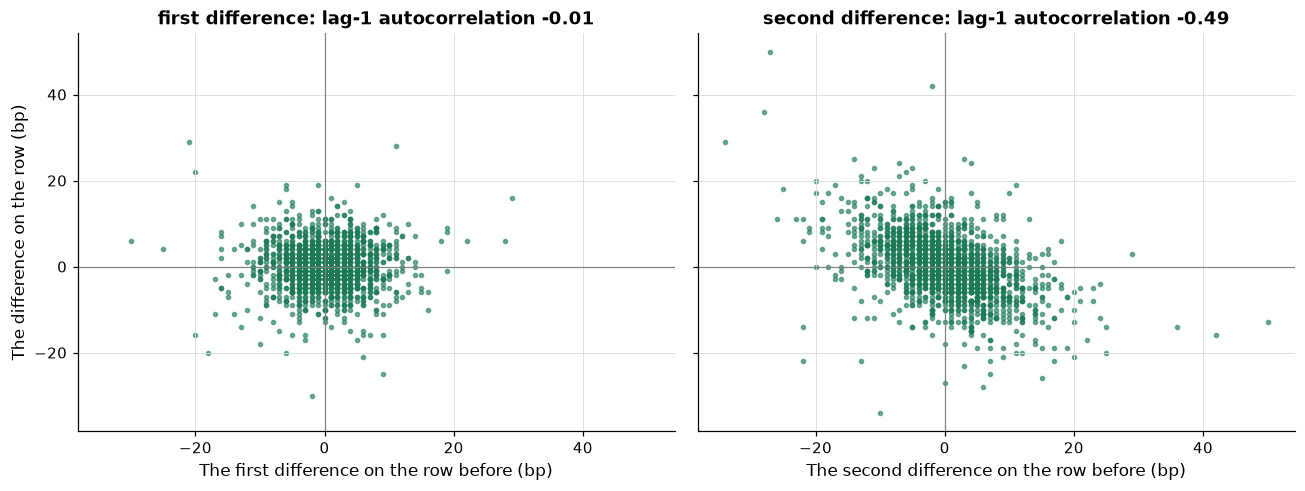

In [36]:
# each date's difference against the one before it: the first difference has no pattern, the second slopes down
fig, (left, right) = plt.subplots(1, 2, figsize=(12, 4.6), sharex=True, sharey=True)
for ax, series, name in ((left, first, "first difference"), (right, second, "second difference")):
    ax.scatter(series.iloc[:-1], series.iloc[1:], s=7, color=plotkit.GREEN, alpha=0.6)
    ax.axhline(0, color=plotkit.GREY, linewidth=0.8)
    ax.axvline(0, color=plotkit.GREY, linewidth=0.8)
    ax.set_xlabel(f"The {name} on the row before (bp)")
    ax.set_title(f"{name}: lag-1 autocorrelation {series.autocorr(1):.2f}")
left.set_ylabel("The difference on the row (bp)")
fig.tight_layout()
plt.show()

* The second difference passes the ADF test too (p-value near zero), which is the trap: the test cannot tell you that you differenced too much. Its standard deviation is 7.14 bp against 5.03 for the first difference, and the lag-1 autocorrelation is -0.485 against -0.007. The right panel's downward slope is that -0.5: each second difference partly undoes the one before it. **Difference once, test, and stop.**

Q. Does a log help? Compare the spread of changes in the second half with the first half, in points and in logs, for a simulated index that compounds and for the 10 Yr.

In [37]:
# a compounding index: each day it moves by about 1 percent, so its moves in points grow with its level
rng = np.random.default_rng(SEED)
index = pd.Series(100 * np.exp((0.001 + 0.01 * rng.standard_normal(2_000)).cumsum()))
half = len(index) // 2


def spread_ratio(series):
    """The standard deviation of the second half of a series of changes over the first half's."""
    return float(series.iloc[half:].std() / series.iloc[:half - 1].std())


ten_year = levels["10 Yr"]
ratios = pd.DataFrame({
    "change in points": [spread_ratio(index.diff().dropna()), spread_ratio(ten_year.diff().dropna())],
    "change in logs": [spread_ratio(np.log(index).diff().dropna()), spread_ratio(np.log(ten_year).diff().dropna())],
}, index=pd.Index(["compounding index", "10 Yr level in bp"], name="Spread of changes, second half over first half"))
print(f"the index runs from {index.iloc[0]:.0f} to {index.max():.0f}")
print(ratios.round(2).to_string())

plotkit.styled(ratios, [], "Spread of changes, second half over first half: in points and in logs", fmt="{:.2f}")

the index runs from 100 to 348
                                                change in points  change in logs
Spread of changes, second half over first half                                  
compounding index                                           1.92            1.03
10 Yr level in bp                                           1.32            2.03


,change in points,change in logs
"Spread of changes, second half over first half",,
compounding index,1.92,1.03
10 Yr level in bp,1.32,2.03


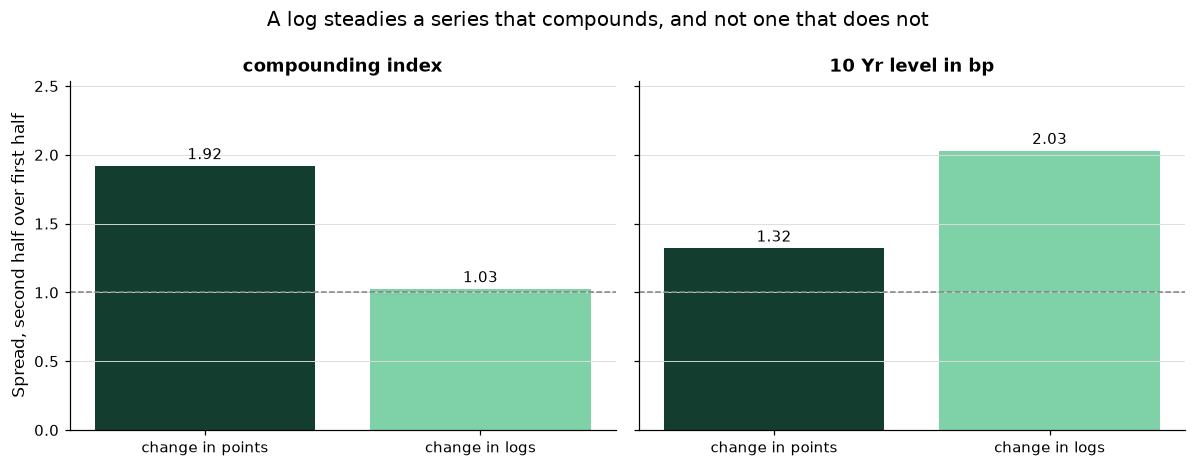

In [38]:
# the spread of the changes in the second half over the first half: 1 means the spread did not move
fig, axes = plt.subplots(1, 2, figsize=(11, 4.3), sharey=True)
for ax, name in zip(axes, ratios.index):
    bars = ax.bar(["change in points", "change in logs"], ratios.loc[name].to_numpy(), color=[plotkit.GREEN_DARK, plotkit.GREEN_LIGHT])
    ax.bar_label(bars, fmt="{:.2f}", fontsize=10, padding=2)
    ax.axhline(1, color=plotkit.GREY, linestyle="--", linewidth=1)
    ax.set_title(name)
    ax.grid(axis="x", visible=False)
axes[0].set_ylabel("Spread, second half over first half")
axes[0].set_ylim(0, ratios.to_numpy().max() * 1.25)
fig.suptitle("A log steadies a series that compounds, and not one that does not")
fig.tight_layout()
plt.show()

* For the compounding index (it runs from 100 to 348), the spread of changes in points is 1.92 times larger in the second half, and in logs it is 1.03: the log steadies it. For the 10 Yr, the log makes it **worse**, 2.03 against 1.32, because the yield fell as low as 52 bp and the same move in bp is a very large move in logs. A log suits a series whose moves scale with its level. Yields and spreads in bp do not, so this course differences the level and does not take logs.

## 3.6 The Stationarity Checklist

Q. What are the five steps, in order, with the tool for each?

In [39]:
# the stationarity checklist, in the order to run it
checklist = pd.DataFrame({
    "Question": ["Does the level wander?", "Does the spread of the changes move?", "What do ADF and KPSS say?",
                 "Did differencing once settle it?", "Did differencing twice add noise?"],
    "Tool": ["a trailing mean and standard deviation, drawn", "the same, on the changes", "adf_summary and kpss_summary, side by side",
             "both tests again, on the changes", "the lag-1 autocorrelation of the second difference"],
    "If yes": ["difference it, or model the change", "expect volatility models (day 7)", "use the four readings table",
               "stop: one difference is enough", "go back to one difference (a value near -0.5 is the sign)"],
}, index=pd.Index(["1", "2", "3", "4", "5"], name="Step"))

plotkit.styled(checklist, [], "The stationarity checklist, in the order to run it")

,Question,Tool,If yes
Step,,,
1,Does the level wander?,"a trailing mean and standard deviation, drawn","difference it, or model the change"
2,Does the spread of the changes move?,"the same, on the changes",expect volatility models (day 7)
3,What do ADF and KPSS say?,"adf_summary and kpss_summary, side by side",use the four readings table
4,Did differencing once settle it?,"both tests again, on the changes",stop: one difference is enough
5,Did differencing twice add noise?,the lag-1 autocorrelation of the second difference,go back to one difference (a value near -0.5 is the sign)


* Run it before every model. Days 4 and 5 start from its answer: the 10 Yr's change is stationary, with no memory worth the name, and its size is where the memory is.

## Excel Side by Side

**Excel has no ADF test and no KPSS test.** Neither is a worksheet function, and the p-value of the ADF test needs a table of critical values that Excel does not hold. What Excel does have is every piece the tests are made of. Each formula below was typed into Excel by script (Excel 16.0 build 20430, 2026-10-21) on the 10 Yr and the invented IG spread in bp: dates in column A, the 10 Yr in B, the IG spread in C, and the day's change of each in D and E (`=B3-B2`, `=C3-C2`).

| Job | Python | Excel | Excel returned |
| --- | --- | --- | --- |
| A trailing mean of 252 | `lv.rolling(252).mean().iloc[-1]` | `=AVERAGE(B1751:B2002)` | 293.3651 |
| A trailing spread of 252 | `lv.rolling(252).std().iloc[-1]` | `=STDEV.S(B1751:B2002)` | 72.6491 |
| The same on the change | `ch.rolling(252).std().iloc[-1]` | `=STDEV.S(D1751:D2002)` | 7.7502 |
| AR(1): phi | `np.polyfit(lag, level, 1)[0]` | `=SLOPE(B3:B2002,B2:B2001)` | 0.999168 |
| AR(1): constant | `np.polyfit(lag, level, 1)[1]` | `=INTERCEPT(B3:B2002,B2:B2001)` | 0.2609 |
| Dickey-Fuller slope (phi - 1) | change on lagged level | `=SLOPE(D3:D2002,B2:B2001)` | -0.000832 |
| Dickey-Fuller statistic | `adf_summary(..., maxlag=0, autolag=None)` | `=INDEX(LINEST(D3:D2002,B2:B2001,TRUE,TRUE),1,1)/INDEX(LINEST(D3:D2002,B2:B2001,TRUE,TRUE),2,1)` | -0.5456 |
| R-squared, levels | `np.corrcoef(a, b)[0, 1] ** 2` | `=RSQ(B2:B2002,C2:C2002)` | 0.1389 |
| R-squared, changes | the same on the changes | `=RSQ(D3:D2002,E3:E2002)` | 0.000093 |

**A trailing window is a range that ends on the row.** `AVERAGE` and `STDEV.S` over the last 252 rows (B1751 to B2002) are the last values of `rolling(252).mean()` and `.std()`. Filled down, the range moves with the row, as the window does.

**AR(1) is `SLOPE` and `INTERCEPT`.** The level on the level one row up, `SLOPE(B3:B2002, B2:B2001)`, is phi, and the 10 Yr's is 0.9992: very near 1. That is the unit root's signature in one cell.

**The Dickey-Fuller statistic is a regression and a division.** Regress the day's change on yesterday's level: the slope is phi minus 1, -0.000832. `LINEST` with its statistics switched on returns the slope in its first row and the slope's standard error in the second; the first over the second is the t statistic, -0.5456, which equals the statistic of `adf_summary` with no lagged changes (2,000 observations). Excel stops there: to turn the statistic into a p-value you need Dickey and Fuller's distribution, and Excel has only the normal and t tables. The statistic is -0.55; the 5 percent critical value is about -2.86; so the test does not reject.

**`RSQ` is the spurious regression.** `RSQ(B2:B2002, C2:C2002)` is 0.1389 on the levels; on the changes it is 0.000093. One function shows a high R-squared and a worthless one.

Q. Do Excel's values equal Python's?

In [40]:
# Excel's results, from the course's Excel check, beside Python's
ten, ig = levels["10 Yr"], levels["IG"]
lagged, change = ten.iloc[:-1].to_numpy(), np.diff(ten.to_numpy())
excel_side = pd.DataFrame({
    "Excel": [293.36507936507934, 72.64914355007511, 7.750164980914399, 0.9991681365700325, -0.5456250516088861, 0.13890080688296946, 9.322737182426926e-05],
    "Python": [ten.rolling(252).mean().iloc[-1], ten.rolling(252).std().iloc[-1], ten.diff().rolling(252).std().iloc[-1],
               np.polyfit(lagged, ten.iloc[1:].to_numpy(), 1)[0],
               tskit.adf_summary(ten, regression="c", maxlag=0, autolag=None)["statistic"],
               np.corrcoef(ten, ig)[0, 1] ** 2, np.corrcoef(ten.diff().dropna(), ig.diff().dropna())[0, 1] ** 2],
}, index=pd.Index(["trailing mean", "trailing spread", "trailing spread of the change", "AR(1) phi", "Dickey-Fuller statistic",
                    "R-squared, levels", "R-squared, changes"], name="Quantity"))
excel_side["equal within 1e-9"] = (excel_side["Excel"] - excel_side["Python"]).abs() < 1e-9
plotkit.styled(excel_side, [], "Excel beside Python on the 10 Yr and the invented IG spread", fmt="{:.6f}")

,Excel,Python,equal within 1e-9
Quantity,,,
trailing mean,293.365079,293.365079,True
trailing spread,72.649144,72.649144,True
trailing spread of the change,7.750165,7.750165,True
AR(1) phi,0.999168,0.999168,True
Dickey-Fuller statistic,-0.545625,-0.545625,True
"R-squared, levels",0.138901,0.138901,True
"R-squared, changes",0.000093,0.000093,True


* Every quantity is equal, to within 1e-9. The Dickey-Fuller statistic from `LINEST` and from `adf_summary` are the same number.

## Save the Day with Git

Today's Git step is a branch. A side experiment, here the same ADF test with a trend in the regression, gets its own branch, so the main line stays as it was and the difference between the two is one command.

Q. Start a repository in the work folder.

In [41]:
# stop here, with the steps to install it, if Git is not on this machine
if shutil.which("git") is None:
    raise RuntimeError("Git is not installed. Install Git for Windows from https://git-scm.com/downloads "
                       "(or run  winget install --id Git.Git  where your firm allows it), restart VS Code, "
                       "and run this cell again. Colab has Git already.")

# -C "{work}" points every Git command at the work folder, whatever folder the notebook is in
!git -C "{work}" --version
# make the work folder a repository
!git -C "{work}" init -q -b main
# settings for this repository only: a course name, a reserved example email, line endings left as they are,
# and no commit signing, so a signing setup on your machine does not ask for a key here
!git -C "{work}" config user.name "Course Student"
!git -C "{work}" config user.email "student@example.com"
!git -C "{work}" config core.autocrlf false
!git -C "{work}" config commit.gpgsign false

git version 2.50.1.windows.1

Q. Is Git working in the work folder, and only there?

In [42]:
# the guard: Git must report the work folder as the top of this repository, or the notebook stops
top = subprocess.run(["git", "-C", str(work), "rev-parse", "--show-toplevel"],
                     capture_output=True, text=True, check=True).stdout.strip()
assert os.path.samefile(top, work), "Git is not working in the work folder. Stop, and run the setup cell again."
print(f"Git is working in {work.name} and nowhere else")

Git is working in pfi_course5b_03_6zaz9nz_ and nowhere else


Q. Tell Git which files never to track, then commit the code.

In [43]:
%%writefile .gitignore
__pycache__/
.pytest_cache/
*.xlsx

Writing .gitignore


In [44]:
!git -C "{work}" add .gitignore mlkit.py tskit.py test_tskit.py
!git -C "{work}" commit -q -m "Day 3: tskit with adf_summary and kpss_summary"
!git -C "{work}" show --stat --format=%s HEAD

Day 3: tskit with adf_summary and kpss_summary

 .gitignore    |   3 +
 mlkit.py      | 568 ++++++++++++++++++++++++++++++++++++++++++++++++++++++++++
 test_tskit.py | 246 +++++++++++++++++++++++++
 tskit.py      | 299 +++++++++++++++++++++++++++++++
 4 files changed, 1116 insertions(+)


Q. Save the test table, and commit it on the main line.

In [45]:
# the test results as a file: dates are not involved; 4 decimals and LF line endings, so a later diff shows a real change
real_tests.round(4).to_csv("stationarity.csv", float_format="%.4f", lineterminator="\n")
print((work / "stationarity.csv").read_text(encoding="utf-8"))

series,form,ADF p-value,KPSS p-value,KPSS p-value is,lags used,reading
2 Yr,levels,0.9779,0.0100,at most 0.01,19,unit root: difference it
2 Yr,changes,0.0000,0.0100,at most 0.01,18,both reject: look for a shift in mean or variance
10 Yr,levels,0.8699,0.0194,inside the table,10,unit root: difference it
10 Yr,changes,0.0000,0.1000,at least 0.1,9,stationary
2s10s,levels,0.7879,0.0100,at most 0.01,22,unit root: difference it
2s10s,changes,0.0000,0.1000,at least 0.1,22,stationary
IG,levels,0.5529,0.0100,at most 0.01,12,unit root: difference it
IG,changes,0.0000,0.1000,at least 0.1,11,stationary
HY,levels,0.0793,0.0100,at most 0.01,0,unit root: difference it
HY,changes,0.0000,0.1000,at least 0.1,0,stationary



In [46]:
!git -C "{work}" add stationarity.csv
!git -C "{work}" commit -q -m "Day 3: the stationarity table"

Q. Start a branch for the experiment, write its file, and commit it there.

In [47]:
# -c makes a branch and switches to it; the star marks the branch you are on
!git -C "{work}" switch -q -c trend
!git -C "{work}" branch

  main


* trend


In [48]:
# the same ADF test with a trend in the regression, on the levels, written to its own file
trend = pd.DataFrame({column: tskit.adf_summary(levels[column], regression="ct") for column in levels.columns}).T
trend[["statistic", "p_value"]].astype(float).round(4).to_csv("stationarity_ct.csv", float_format="%.4f", lineterminator="\n")
print((work / "stationarity_ct.csv").read_text(encoding="utf-8"))

,statistic,p_value
2 Yr,0.0134,0.9944
10 Yr,-0.5326,0.9821
2s10s,-1.5204,0.8221
IG,-1.9922,0.6057
HY,-3.0626,0.1154



In [49]:
!git -C "{work}" add stationarity_ct.csv
!git -C "{work}" commit -q -m "Day 3: ADF with a trend on the levels"

Q. What does the branch hold that the main line does not? Then go back to the main line.

In [50]:
# diff --stat main trend lists the files the two lines differ in; switch -q main goes back
!git -C "{work}" diff --stat main trend
!git -C "{work}" switch -q main
!git -C "{work}" branch
!git -C "{work}" log --oneline main
!git -C "{work}" log --oneline trend

 stationarity_ct.csv | 6 ++++++
 1 file changed, 6 insertions(+)


* main
  trend


39b9b85 Day 3: the stationarity table
9cfe84d Day 3: tskit with adf_summary and kpss_summary


5f6e0b0 Day 3: ADF with a trend on the levels
39b9b85 Day 3: the stationarity table
9cfe84d Day 3: tskit with adf_summary and kpss_summary


* The branch `trend` holds one file the main line does not, `stationarity_ct.csv`: the ADF test with a trend, on the levels. Every p-value in it is above 0.05, so the trend changes no reading. If the experiment had been worth keeping, `git merge trend` would bring it in; if not, the branch is deleted and the main line never knew.

## Bring It Home

Add today's functions to your own `my_bondmath` folder. Open a PowerShell terminal in VS Code.

**Step 1.** Go to your folder and activate the course's environment.

```powershell
Set-Location "$HOME\projects\python-fixed-income"
.\.venv\Scripts\Activate.ps1
Set-Location "$HOME\projects\my_bondmath"
```

**Step 2.** Open `tskit.py` and paste the code of today's two `tskit.py` cells (section 3.3) at the end, without their first lines. Do the same for the two `test_tskit.py` cells in `test_tskit.py`. Save both.

**Step 3.** Run the tests.

```powershell
python -m pytest -q test_tskit.py
```

The last line says `18 passed`.

**Step 4.** Commit.

```powershell
git add tskit.py test_tskit.py
git commit -m "Day 3: tskit with adf_summary and kpss_summary"
```

## You Can Now

* Say what stationary means, and see how phi changes a series from one that keeps returning to its average to one that wanders.
* Draw a trailing mean and spread, and tell a level that wanders from a change that does not.
* Run ADF and KPSS (`adf_summary`, `kpss_summary`), read each with its own null hypothesis, and read the two together with the four cases.
* Read every setting of both tests, and say which ones move a verdict and which do not.
* Recognise a spurious regression, and explain why a high R-squared between two levels proves nothing.
* Difference once, stop, and know what over-differencing and a log each do.
* Say what the five development series look like: all five levels read as a unit root, four of the five changes read as stationary, and the 2 Yr's changes shift with the years.

Next, day 4: autocorrelation, the ACF and the PACF: what memory a stationary series has, and which AR or MA order its picture suggests.

## Exercises

**Every exercise has a worked answer** in the solutions notebook in this folder: the one with this notebook's name ending in `_solutions.ipynb`. Give each exercise a real try first, then check your work against it.

Replace each `...` with your own code, then run the check cell.

Q. Run the next cell first. It loads the five series as section 3.1 does, runs both tests on each series in levels and in changes as section 3.3 does (`real_tests`), and defines `check`, a small function that marks your answers.

In [51]:
# the Treasury curve (percent) and the course's synthetic spreads (bp): one row per date, the same dates in both files
treasury = pd.read_csv("treasury_par_yields.csv", parse_dates=["date"]).set_index("date")
spreads = pd.read_csv("course3_synthetic_spreads.csv", parse_dates=["date"]).set_index("date")
print(f"Treasury file: {len(treasury):,} dates; spread file: {len(spreads):,} dates; same dates: {treasury.index.equals(spreads.index)}")

# the development and held-out years, set now, before any model is fitted
DEVELOPMENT_END = "2022-12-30"
development = treasury.loc[:DEVELOPMENT_END]
dev_spreads = spreads.loc[:DEVELOPMENT_END]
held_out_dates = treasury.index[treasury.index > DEVELOPMENT_END]
print(f"development years: {len(development):,} dates, {development.index[0].date()} to {development.index[-1].date()}")
print(f"held-out years: {len(held_out_dates):,} dates, {held_out_dates[0].date()} to {held_out_dates[-1].date()}, not opened until the capstone")

# five series, all in bp: yields times 100 (rounded to the file's two decimals of a percent), spreads as they are
levels = pd.DataFrame({
    "2 Yr": (development["2 Yr"] * 100).round(2),
    "10 Yr": (development["10 Yr"] * 100).round(2),
    "2s10s": ((development["10 Yr"] - development["2 Yr"]) * 100).round(2),
    "IG": dev_spreads["ig_spread_bp"],
    "HY": dev_spreads["hy_spread_bp"],
})
# nothing below reads a held-out row: drop the full tables
del treasury, spreads, development, dev_spreads
print(f"five series in bp: {list(levels.columns)}; blank cells: {int(levels.isna().sum().sum())}")

# the walk-forward windows of section 2.5, used by every later day: fit on 504 dates first, then score 252 at a time
MIN_TRAIN, TEST_SIZE = 504, 252
# both tests on each series in levels and in changes, and what the pair says (the table above gives the four readings)
verdicts = {
    (True, False): "stationary",
    (False, True): "unit root: difference it",
    (True, True): "both reject: look for a shift in mean or variance",
    (False, False): "inconclusive: neither rejects",
}
rows = []
for column in levels.columns:
    for form, series in (("levels", levels[column]), ("changes", levels[column].diff().dropna())):
        adf, kp = tskit.adf_summary(series), tskit.kpss_summary(series)
        rows.append({"series": column, "form": form, "ADF p-value": adf["p_value"], "KPSS p-value": kp["p_value"],
                     "KPSS p-value is": kp["p_note"], "lags used": adf["lags_used"],
                     "reading": verdicts[(adf["rejects_unit_root"], kp["rejects_stationarity"])]})
real_tests = pd.DataFrame(rows).set_index(["series", "form"])
print(real_tests.to_string())


def check(label, answer, expected):
    """Compare an exercise answer with the expected value and print the result."""
    if answer is ...:
        print(f"{label}: not attempted yet")
        return
    if isinstance(expected, float):
        # numbers with a decimal point: within a small tolerance
        correct = abs(answer - expected) < 1e-6
    else:
        correct = answer == expected
    if correct:
        print(f"{label}: correct")
    else:
        print(f"{label}: not yet. You have {answer}.")

Treasury file: 2,940 dates; spread file: 2,940 dates; same dates: True
development years: 2,001 dates, 2015-01-02 to 2022-12-30
held-out years: 939 dates, 2023-01-03 to 2026-10-02, not opened until the capstone
five series in bp: ['2 Yr', '10 Yr', '2s10s', 'IG', 'HY']; blank cells: 0


                 ADF p-value  KPSS p-value   KPSS p-value is  lags used                                            reading
series form                                                                                                               
2 Yr   levels   9.779276e-01      0.010000      at most 0.01         19                           unit root: difference it
       changes  2.569658e-12      0.010000      at most 0.01         18  both reject: look for a shift in mean or variance
10 Yr  levels   8.699105e-01      0.019362  inside the table         10                           unit root: difference it
       changes  2.089351e-24      0.100000      at least 0.1          9                                         stationary
2s10s  levels   7.879405e-01      0.010000      at most 0.01         22                           unit root: difference it
       changes  1.003564e-12      0.100000      at least 0.1         22                                         stationary
IG     levels   

### Exercise 1

Q. How many of the five series have changes that KPSS rejects as stationary at 5 percent? Store the count in **ex1_kpss_rejects** (the `KPSS p-value` column of `real_tests`, rows with form `changes`). Which series is it, and what did section 3.3 find?

In [52]:
ex1_kpss_rejects = ...

In [53]:
check("Exercise 1 KPSS rejections on the changes", ex1_kpss_rejects, 1)

Exercise 1 KPSS rejections on the changes: not attempted yet


### Exercise 2

Q. Run the ADF test on the 10 Yr's **level** with a trend in the regression (`regression="ct"`) and store its p-value in **ex2_p_value**. Does the trend rescue the level?

In [54]:
ex2_p_value = ...

In [55]:
check("Exercise 2 ADF p-value with a trend", ex2_p_value, 0.9820980227341173)

Exercise 2 ADF p-value with a trend: not attempted yet


### Exercise 3

Q. Add a function to your module. `stationary_verdict(adf_p, kpss_p, level=0.05)` reads the two p-values together and returns one of four strings (the table of four readings: `"stationary"`, `"unit root: difference it"`, `"both reject: look for a shift in mean or variance"`, `"inconclusive: neither rejects"`). It refuses a p-value outside 0 to 1 and a level outside 0 to 1 with `ValueError`. Write the docstring first. Add `test_stationary_verdict_four_cases` with the four cases, a level that moves the boundary, and both refusals. Run pytest, reload the module, and store the verdict for the 2 Yr's changes in **ex3_verdict**.

Write the function in the cell that starts with `%%writefile -a tskit.py` and the test in the one that starts with `%%writefile -a test_tskit.py`, and run each of those cells once.

In [56]:
%%writefile -a tskit.py


# Exercise 3: write stationary_verdict(adf_p, kpss_p, level=0.05) below this line

Appending to tskit.py


In [57]:
%%writefile -a test_tskit.py


# Exercise 3: write test_stationary_verdict_four_cases() below this line

Appending to test_tskit.py


In [58]:
# run pytest, reload the module, then use your function on the 2 Yr's changes
ex3_verdict = ...

In [59]:
check("Exercise 3 verdict for the 2 Yr changes", ex3_verdict, 'both reject: look for a shift in mean or variance')

Exercise 3 verdict for the 2 Yr changes: not attempted yet


### Exercise 4

Q. Difference the invented IG spread **twice** and take the lag-1 autocorrelation of the second difference (`Series.autocorr(1)`). Store it in **ex4_autocorrelation**. What number should an over-differenced series give?

In [60]:
ex4_autocorrelation = ...

In [61]:
check("Exercise 4 autocorrelation of a second difference", ex4_autocorrelation, -0.4924018865549719)

Exercise 4 autocorrelation of a second difference: not attempted yet


### Exercise 5: AI check

You ask an AI assistant for a function that says whether a series is stationary, and you give it a docstring as the request. **The docstring is the prompt.** This is what you gave it:

```
True when a series is stationary according to the ADF test.

    The ADF test's null hypothesis is a unit root, so a stationary series is one for which the test
    rejects the null: its p-value is below the level (default 0.05).
    Returns a bool; the input is not changed.
```

The function below came back. It was written for this course in the style of an AI assistant's answer. It runs without an error, returns a bool, and contains one bug.

In [62]:
# written for this course in the style of an AI assistant's answer. It runs, and it contains one bug.
from statsmodels.tsa.stattools import adfuller


def is_stationary(series, level=0.05):
    """True when a series is stationary according to the ADF test.

    The ADF test's null hypothesis is a unit root, so a stationary series is one for which the test
    rejects the null: its p-value is below the level (default 0.05).
    Returns a bool; the input is not changed.
    """
    # a p-value above the level means the test found nothing wrong with the series, so it passes
    p_value = adfuller(series.dropna(), result_object=True).pvalue
    return bool(p_value > level)

Q. Before you run the next cell: a random walk and white noise. Which one is stationary? What does the function say about each?

In [63]:
rng = np.random.default_rng(SEED)
noise = pd.Series(rng.standard_normal(500))
walk = noise.cumsum()
print(f"random walk called stationary -> {is_stationary(walk)}")
print(f"white noise called stationary -> {is_stationary(noise)}")

random walk called stationary -> True
white noise called stationary -> False


Q. Test the function against its docstring before you trust it.

In [64]:
# the test, written from the docstring before the code is trusted
rng = np.random.default_rng(SEED)
noise = pd.Series(rng.standard_normal(500))
walk = noise.cumsum()
assert not is_stationary(walk), "a random walk was called stationary: its ADF p-value is large, and a large p-value does not reject the unit root"
assert is_stationary(noise), "white noise was called not stationary: its ADF p-value is tiny, which rejects the unit root"
print("the walk is not stationary, the noise is")

AssertionError: a random walk was called stationary: its ADF p-value is large, and a large p-value does not reject the unit root

Q. Read the test's message, fix the function in the cell that defines it, and run that cell and the test again until the test passes. Then store what the fixed function says about the random walk in **ex5_walk_stationary**.

In [65]:
# fix the function above and run the test again, then store the answer
ex5_walk_stationary = ...

In [66]:
check("Exercise 5 the walk called stationary", ex5_walk_stationary, False)

Exercise 5 the walk called stationary: not attempted yet


## Tidying Up

The work folder stays where it is, so you can open it: its name was printed by the setup cell, and on Windows it is under `$env:TEMP`. Every run of the setup cell makes a new one. To delete a work folder, run these lines in a cell of the same notebook session. Git marks its own files read-only, and on Windows a plain delete stops at them with a `PermissionError`, so the handler clears that flag and tries again.

```python
import stat

def clear_read_only(function, path, error):
    """Make a read-only file writable, then retry the delete that failed on it."""
    os.chmod(path, stat.S_IWRITE)
    function(path)

os.chdir(notebook_folder)
shutil.rmtree(work, onexc=clear_read_only)
print(f"{work.name} exists: {work.exists()}")
```